# Bitcoin Price Forecasting with LSTM -  Multi-horizon
Forecast Price at h = 1, 3, 5, 7, 14, 21, 30 calendar days using a 60-day log-return input and 30-output MIMO LSTM.
Only Price supplies model inputs; other columns are cleaned for data quality and EDA.

**Run:** choose **Python 3.12 (vs_nine TensorFlow)**, then **Restart Kernel and Run All Cells**.
There is no validation, early stopping, hyperparameter tuning, or model comparison. Each of the five preselected seeds is trained once for 50 epochs; all seeds enter the ensemble equally. Weights and scaler remain fixed throughout test and future forecasting.
The raw split is chronological 80/20. Historical test forecasts and future forecasts are shown separately.

Outputs: `PROJECT_2026/OUTPUT/outputs_lstm/{tables,figures,models}`. This notebook remains `LSTM_BTC.ipynb`; no additional notebook or helper script is needed.


## Step 1 - Environment Setup and Fixed Configuration


In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import sys
import random
import json
import hashlib
import time
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
import statsmodels
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import scipy
from scipy import stats
from IPython.display import display, Markdown, HTML

DATA_PATH = 'Bitcoin_Historical_Data.csv'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
MAX_H = 30
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
LOOKBACK = 60
EPOCHS = 50
BATCH_SIZE = 32
LR = 0.001
DROPOUT = 0.1
SEEDS = [0, 1, 2, 3, 4]
ALPHA = 0.05
SHOW_NAIVE_REFERENCE = False
assert max(HORIZONS) == MAX_H
assert max(DAILY_FORECAST_WINDOWS) <= MAX_H

# Runtime CPU threading does not change the model architecture or hyperparameters.
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)
set_seed(SEEDS[0])

search_dirs = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((base for base in search_dirs
    if (base / 'BTC_TEST').is_dir() and (base / 'CSV').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch JupyterLab inside PROJECT_2026 or BTC_TEST.')
data_file = Path(DATA_PATH)
if not data_file.is_file():
    candidates = [base / rel for base in search_dirs for rel in
        ['Bitcoin_Historical_Data.csv', 'BTC_TEST/Bitcoin_Historical_Data.csv',
         'CSV/Bitcoin Historical Data.csv', 'CSV/Bitcoin_Historical_Data.csv']]
    data_file = next((candidate for candidate in candidates if candidate.is_file()), data_file)
if not data_file.is_file():
    raise FileNotFoundError('Set DATA_PATH to the Bitcoin CSV.')
DATA_PATH = str(data_file.resolve())
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT' / 'outputs_lstm'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
MODEL_DIR = OUTPUT_DIR / 'models'
for directory in [TABLE_DIR, FIGURE_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.25, 'figure.dpi': 110})
versions = pd.DataFrame([(name, version(name)) for name in
    ['pandas','numpy','matplotlib','scikit-learn','tensorflow','keras','statsmodels','scipy']],
    columns=['library','version'])
print('Python:', sys.version, '\nExecutable:', sys.executable)
display(versions)
print('Data:', DATA_PATH, '\nOutputs:', OUTPUT_DIR)
versions.to_csv(TABLE_DIR / 'library_versions.csv', index=False)

def save_table(frame, name):
    frame.to_csv(TABLE_DIR / name, index=False, encoding='utf-8-sig')
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def weights_digest(model):
    digest = hashlib.sha256()
    for weight in model.get_weights():
        digest.update(np.ascontiguousarray(weight).tobytes())
    return digest.hexdigest()
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:,.2f}') + '</div>'))


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,scikit-learn,1.9.1
4,tensorflow,2.21.0
5,keras,3.15.1
6,statsmodels,0.15.0
7,scipy,1.18.1


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\Bitcoin Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_lstm


## Step 2 - Data Preparation
Convert source strings, sort oldest to newest, and establish a daily calendar index without imputing prices.
Keep volume B rows; volume is not a model feature. The first log return is necessarily NaN and is excluded from scaler fitting and all windows.


In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date','Price','Open','High','Low','Vol.','Change %']
assert set(required).issubset(raw.columns)
assert not raw[required].isna().any().any()
df = raw[required].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='raise')
assert not df['Date'].duplicated().any(), 'Duplicate dates'
df = df.sort_values('Date')
for column in ['Price','Open','High','Low']:
    df[column] = pd.to_numeric(df[column].str.replace(',', '', regex=False), errors='raise').astype(float)
vol = df['Vol.'].str.strip().str.upper().str.replace(',', '', regex=False)
parts = vol.str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unknown volume format'
df['Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol.str.endswith('B')].copy()
save_table(b_rows, 'volume_B_rows.csv')
print('Volume B rows retained:', len(b_rows))
df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
df = df.drop(columns='Vol.').set_index('Date').asfreq('D')
assert df.index.is_monotonic_increasing and df.index.is_unique
assert not df.isna().any().any(), 'Missing data or calendar gaps'
assert np.isfinite(df.to_numpy()).all() and (df['Price'] > 0).all()
assert len(df) == 1897
assert df.index[0] == pd.Timestamp('2021-07-01') and df.index[-1] == pd.Timestamp('2026-09-09')
log_price = np.log(df['Price']).rename('log_price')
log_ret = log_price.diff().rename('log_ret')
assert pd.isna(log_ret.iloc[0]) and log_ret.iloc[1:].notna().all()
display(df.head())


Volume B rows retained: 16


,Price,Open,High,Low,Change %,Volume
Date,,,,,,
2021-07-01,33543.6,35030.7,35032.7,32839.2,-0.0423,27410.0
2021-07-02,33813.4,33542.2,33925.9,32734.6,0.0080,78930.0
2021-07-03,34742.8,33814.2,34909.8,33363.3,0.0275,55690.0
2021-07-04,35298.2,34742.8,35957.6,34740.1,0.0160,56130.0
2021-07-05,33687.8,35297.0,35300.5,33164.1,-0.0456,88360.0


## Step 3 - EDA (Descriptive Only; No Model Decisions)


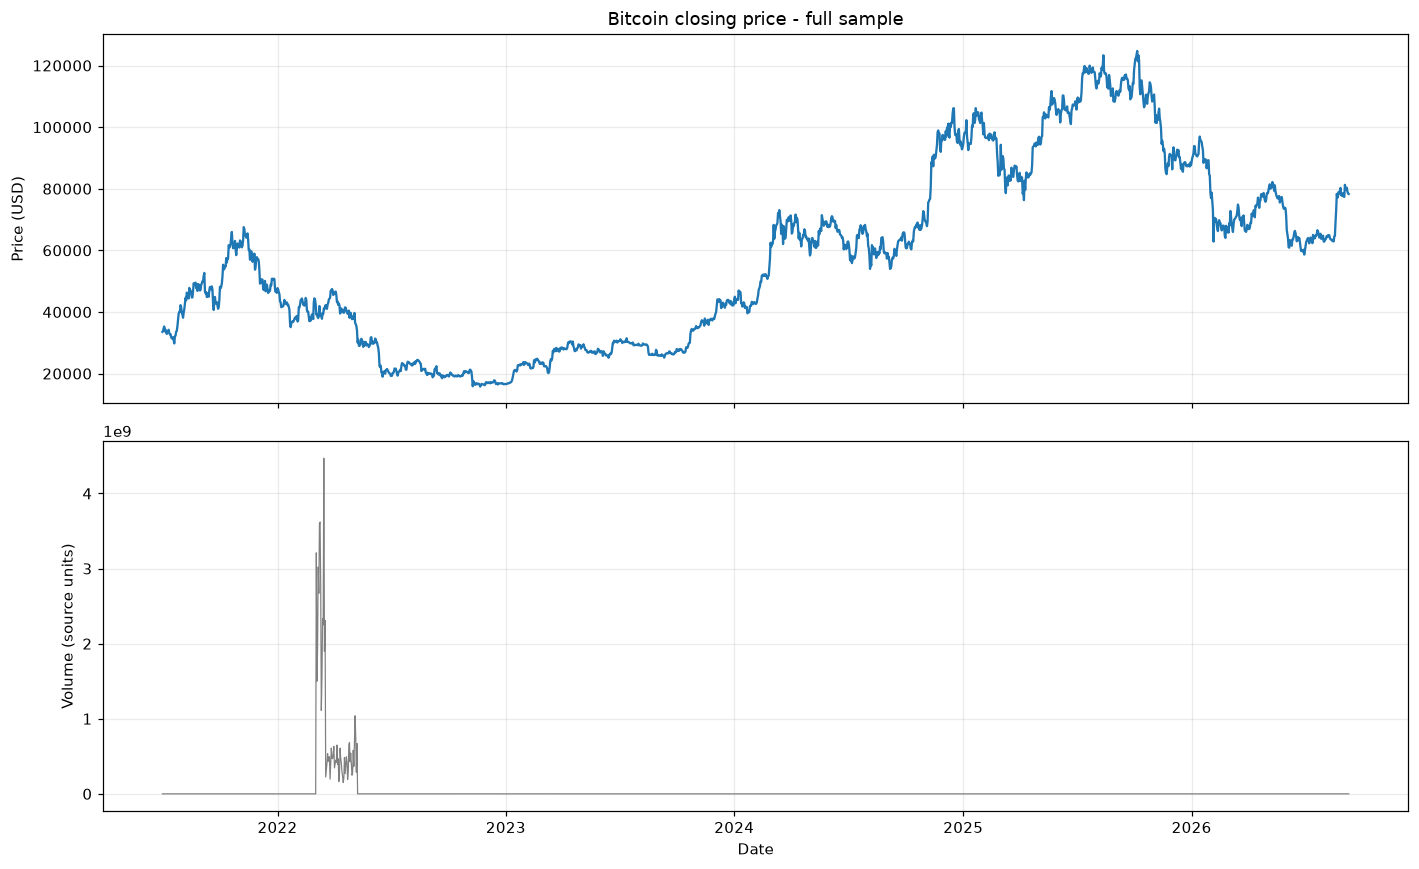

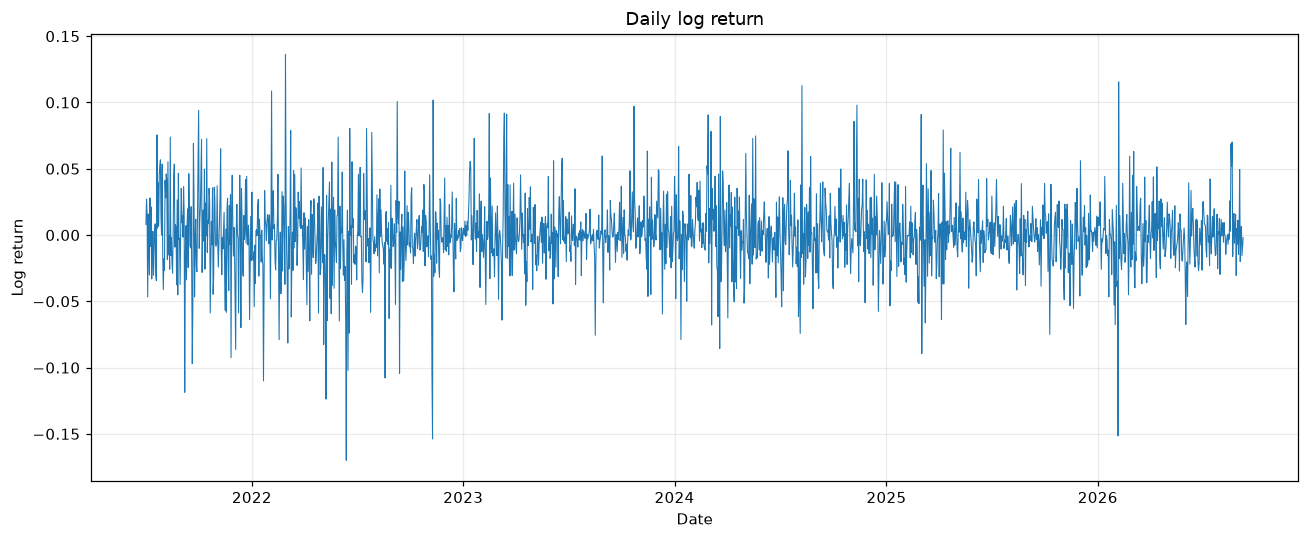

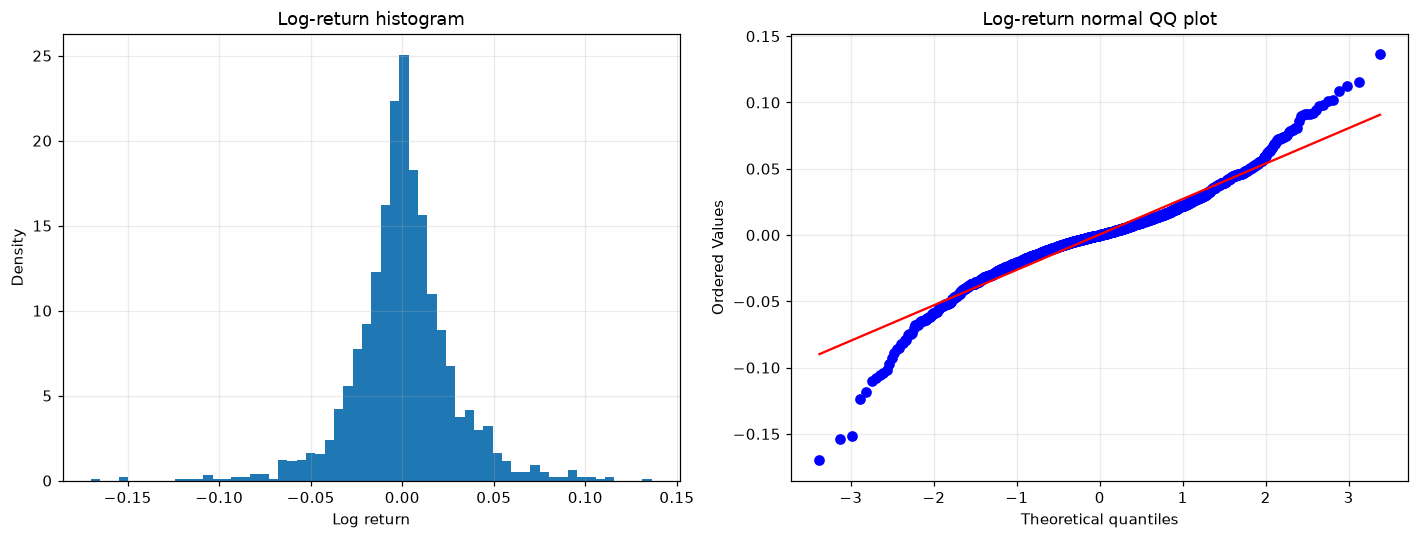

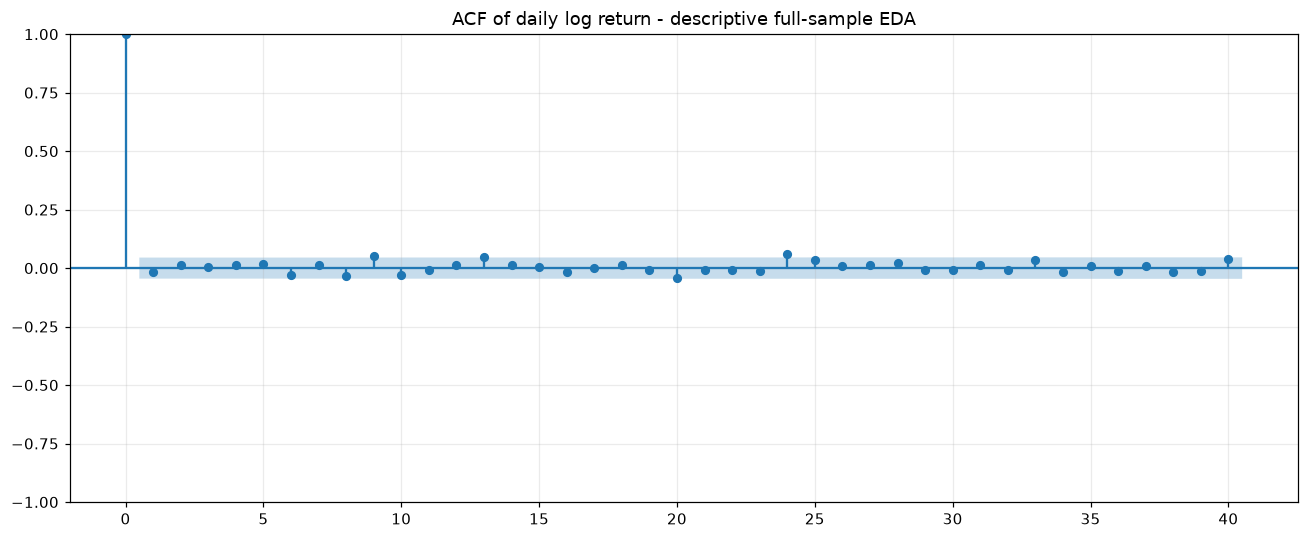

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df.index, df['Price'])
axes[0].set(title='Bitcoin closing price - full sample', ylabel='Price (USD)')
axes[1].plot(df.index, df['Volume'], color='gray', linewidth=0.8)
axes[1].set(ylabel='Volume (source units)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')
fig, ax = plt.subplots()
ax.plot(log_ret, linewidth=0.7)
ax.set(title='Daily log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '02_log_return.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_ret.dropna(), bins=60, density=True)
axes[0].set(title='Log-return histogram', xlabel='Log return', ylabel='Density')
stats.probplot(log_ret.dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '03_return_distribution.png')
fig, ax = plt.subplots()
plot_acf(log_ret.dropna(), lags=40, ax=ax)
ax.set_title('ACF of daily log return - descriptive full-sample EDA')
save_figure(fig, '04_acf_log_return.png')


## Step 4 - Chronological Split BEFORE Scaling and Windowing


,split,start_date,end_date,n_days,price_min,price_max,price_mean,log_ret_n,log_ret_mean,log_ret_std
0,Train,2021-07-01,2025-08-25,1517,15776.2,123323.4,51303.650560,1516,0.000784,0.028476
1,Test,2025-08-26,2026-09-09,380,58630.8,124725.1,82884.701579,380,-0.000897,0.022908


Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).


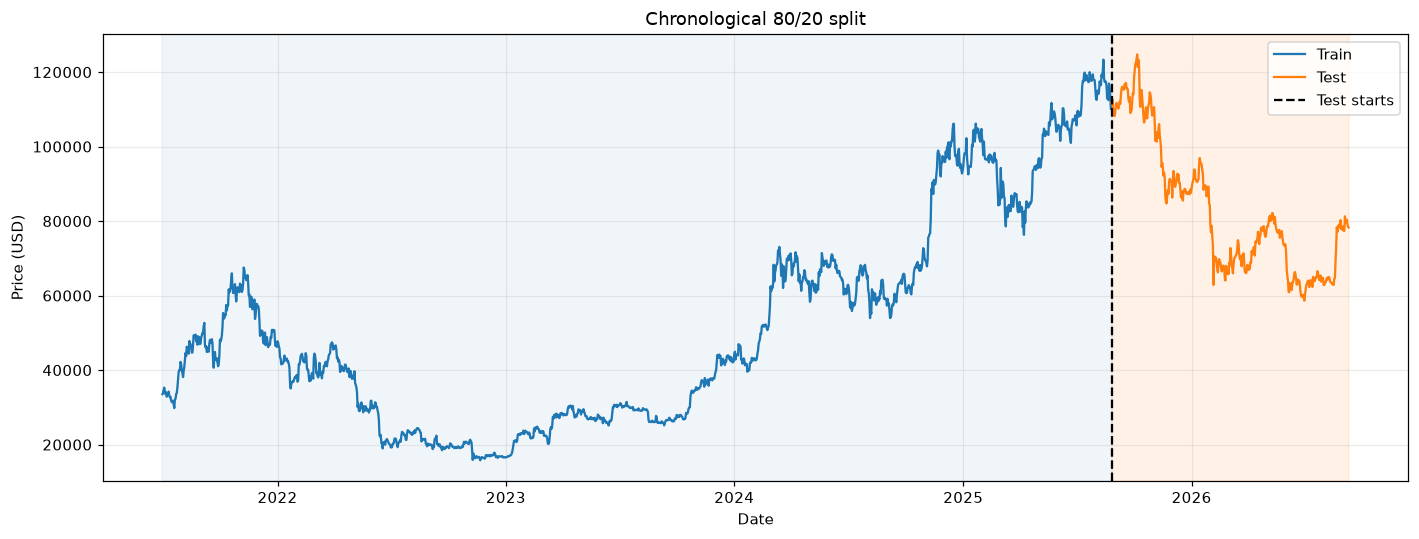

In [4]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
TRAIN_END_IDX = n_train - 1
assert (n_train, n_test, TRAIN_END_IDX) == (1517, 380, 1516)
assert df.index[TRAIN_END_IDX] == pd.Timestamp('2025-08-25')
assert df.index[n_train] == pd.Timestamp('2025-08-26')
train_ret = log_ret.iloc[1:n_train].copy()
split_rows = []
for name, start, end in [('Train', 0, n_train), ('Test', n_train, n)]:
    prices = df['Price'].iloc[start:end]
    returns = log_ret.iloc[start:end].dropna()
    split_rows.append(dict(split=name, start_date=prices.index[0], end_date=prices.index[-1],
        n_days=len(prices), price_min=prices.min(), price_max=prices.max(), price_mean=prices.mean(),
        log_ret_n=len(returns), log_ret_mean=returns.mean(), log_ret_std=returns.std(ddof=1)))
split_summary = pd.DataFrame(split_rows)
save_table(split_summary, 'split_summary.csv')
display(split_summary)
print('Return SD above uses ddof=1; StandardScaler below uses population SD (ddof=0).')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Price'].iloc[:n_train], label='Train', color='tab:blue')
ax.plot(df['Price'].iloc[n_train:], label='Test', color='tab:orange')
ax.axvspan(df.index[0], df.index[n_train], alpha=0.07, color='tab:blue')
ax.axvspan(df.index[n_train], df.index[-1], alpha=0.10, color='tab:orange')
ax.axvline(df.index[n_train], color='black', linestyle='--', label='Test starts')
ax.set(title='Chronological 80/20 split', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '05_train_test_split.png')


## Step 5 - Scaling (Fit on Train Only)
Fit the scaler on return indices 1..1516 only. Transforming later observations with that frozen scaler is permitted for inference; it does not estimate anything from test.
No test values enter the scaler fit or the training windows below.


In [5]:
scaler_fit_indices = np.arange(1, n_train)
assert scaler_fit_indices.max() <= TRAIN_END_IDX
scaler = StandardScaler()
scaler.fit(train_ret.to_numpy().reshape(-1, 1))
assert int(scaler.n_samples_seen_) == len(scaler_fit_indices)
assert train_ret.index.max() <= df.index[TRAIN_END_IDX]
scaler_mean = float(scaler.mean_[0])
scaler_std = float(scaler.scale_[0])
assert scaler_std > 0
np.testing.assert_allclose(scaler_mean, train_ret.mean(), atol=1e-12)
np.testing.assert_allclose(scaler_std, train_ret.std(ddof=0), atol=1e-12)
z = np.full(n, np.nan, dtype=np.float64)
z[1:] = scaler.transform(log_ret.iloc[1:].to_numpy().reshape(-1, 1)).ravel()
assert np.isnan(z[0]) and np.isfinite(z[1:]).all()
scaler_params = dict(mean=scaler_mean, std=scaler_std, ddof=0,
    fit_first_index=int(scaler_fit_indices.min()), fit_last_index=int(scaler_fit_indices.max()),
    n_samples=int(scaler.n_samples_seen_), fit_end_date=str(train_ret.index[-1].date()))
(MODEL_DIR / 'scaler_params.json').write_text(json.dumps(scaler_params, indent=2), encoding='utf-8')
print('Frozen scaler:', scaler_params)


Frozen scaler: {'mean': 0.0007841095418230332, 'std': 0.02846616907695721, 'ddof': 0, 'fit_first_index': 1, 'fit_last_index': 1516, 'n_samples': 1516, 'fit_end_date': '2025-08-25'}


## Step 6 - MIMO Training Windows
X contains 60 scaled returns ending at origin t. y contains the next 30 scaled returns.
Every input and every target lies in train; no validation windows are created.


In [6]:
train_origins = np.arange(LOOKBACK, TRAIN_END_IDX - MAX_H + 1)
train_input_indices = train_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
train_target_indices = train_origins[:, None] + np.arange(1, MAX_H+1)[None, :]
assert train_input_indices.min() >= 1
assert train_input_indices.max() <= TRAIN_END_IDX
assert train_target_indices.max() <= TRAIN_END_IDX
assert (train_input_indices < n_train).all() and (train_target_indices < n_train).all()
X_train = z[train_input_indices][..., None].astype(np.float32)
y_train = z[train_target_indices].astype(np.float32)
assert X_train.shape == (len(train_origins), LOOKBACK, 1)
assert y_train.shape == (len(train_origins), MAX_H)
assert len(train_origins) == TRAIN_END_IDX - MAX_H - LOOKBACK + 1 == 1427
assert np.isfinite(X_train).all() and np.isfinite(y_train).all()
window_audit = pd.DataFrame(dict(origin_idx=train_origins, origin_date=df.index[train_origins],
    input_start_idx=train_input_indices[:, 0], input_end_idx=train_input_indices[:, -1],
    target_start_idx=train_target_indices[:, 0], target_end_idx=train_target_indices[:, -1]))
save_table(window_audit, 'training_window_audit.csv')
print('Training samples:', len(train_origins), 'X:', X_train.shape, 'y:', y_train.shape)
display(window_audit.iloc[[0,-1]])


Training samples: 1427 X: (1427, 60, 1) y: (1427, 30)


,origin_idx,origin_date,input_start_idx,input_end_idx,target_start_idx,target_end_idx
0,60,2021-08-30,1,60,61,90
1426,1486,2025-07-26,1427,1486,1487,1516


## Step 7 - Fixed Architecture (No Tuning)


In [7]:
def build_model():
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        LSTM(64, activation='tanh', return_sequences=True),
        Dropout(DROPOUT),
        LSTM(32, activation='tanh'),
        Dropout(DROPOUT),
        Dense(MAX_H)
    ])
    model.compile(optimizer=Adam(learning_rate=LR), loss='mse')
    return model
preview_model = build_model()
architecture_lines = []
preview_model.summary(print_fn=lambda text, **kwargs: architecture_lines.append(text))
architecture_text = '\n'.join(architecture_lines)
print(architecture_text)
(MODEL_DIR / 'model_architecture.txt').write_text(architecture_text, encoding='utf-8')
model_config = dict(horizons=HORIZONS, max_h=MAX_H, train_ratio=TRAIN_RATIO, lookback=LOOKBACK,
    epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=LR, dropout=DROPOUT, seeds=SEEDS,
    architecture=['LSTM(64,tanh,return_sequences=True)','Dropout(0.1)',
                  'LSTM(32,tanh)','Dropout(0.1)','Dense(30)'], validation=False,
    target='daily_log_return', input='Price only', ensemble='mean of seed log-return forecasts')
(MODEL_DIR / 'model_config.json').write_text(json.dumps(model_config, indent=2), encoding='utf-8')
del preview_model


Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 30)             │           990 │
└─────────────────────────────────┴─────────────────────

## Step 8 - Training Once per Seed, Without Validation
Exactly 50 epochs per seed, fixed settings, no callbacks or early stopping.
`shuffle=True` reorders training samples only; it never changes temporal order inside a window or the chronological raw split.
Training-loss reduction is a process check, not evidence of out-of-sample accuracy. No seed is selected or discarded using test performance.


Training seed 0: 50 fixed epochs


Finished seed 0: loss 0.98623 -> 0.81177


Training seed 1: 50 fixed epochs


Finished seed 1: loss 0.98608 -> 0.81511


Training seed 2: 50 fixed epochs


...

Training seed 3: 50 fixed epochs


Finished seed 3: loss 0.98657 -> 0.81425


Training seed 4: 50 fixed epochs


Finished seed 4: loss 0.98648 -> 0.81008


,seed,first_loss,final_loss,loss_reduced,epochs,seconds
0,0,0.986233,0.811768,True,50,102.202211
1,1,0.986085,0.815113,True,50,94.354111
2,2,0.986178,0.814122,True,50,52.090042
3,3,0.986567,0.814252,True,50,49.273576
4,4,0.986483,0.810080,True,50,49.112404


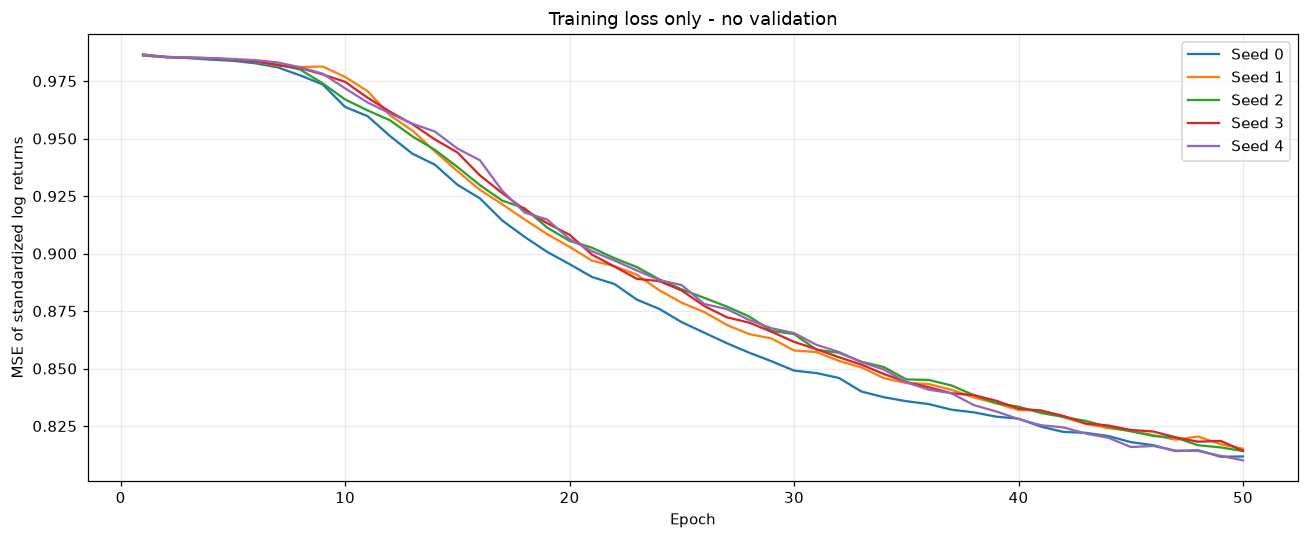

In [8]:
models, frozen_weight_hashes, training_rows, training_audit_rows = {}, {}, [], []
for seed in SEEDS:
    tf.keras.backend.clear_session()
    set_seed(seed)
    model = build_model()
    started = time.perf_counter()
    print(f'Training seed {seed}: {EPOCHS} fixed epochs', flush=True)
    history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0)
    loss = np.asarray(history.history['loss'], dtype=float)
    assert len(loss) == EPOCHS and np.isfinite(loss).all()
    model.save_weights(MODEL_DIR / f'lstm_seed{seed}.weights.h5')
    model.trainable = False
    models[seed] = model
    frozen_weight_hashes[seed] = weights_digest(model)
    training_rows.extend(dict(seed=seed, epoch=epoch, loss=value)
                         for epoch, value in enumerate(loss, 1))
    training_audit_rows.append(dict(seed=seed, first_loss=loss[0], final_loss=loss[-1],
        loss_reduced=bool(loss[-1] < loss[0]), epochs=len(loss), seconds=time.perf_counter()-started,
        weights_sha256=frozen_weight_hashes[seed]))
    save_table(pd.DataFrame(training_rows), 'training_loss.csv')
    save_table(pd.DataFrame(training_audit_rows), 'training_audit.csv')
    print(f'Finished seed {seed}: loss {loss[0]:.5f} -> {loss[-1]:.5f}', flush=True)
training_loss = pd.DataFrame(training_rows)
training_audit = pd.DataFrame(training_audit_rows)
display(training_audit.drop(columns='weights_sha256'))
fig, ax = plt.subplots()
for seed in SEEDS:
    curve = training_loss.loc[training_loss['seed'].eq(seed)]
    ax.plot(curve['epoch'], curve['loss'], label=f'Seed {seed}')
ax.set(title='Training loss only - no validation', xlabel='Epoch', ylabel='MSE of standardized log returns')
ax.legend()
save_figure(fig, '06_training_loss.png')
assert training_audit['loss_reduced'].all(), 'Final training loss must be below first loss in every seed; do not tune using test.'


## Step 9 - Rolling-origin Forecasts with Fixed Weights
Origins in test evaluation are 1516..1895. Each 60-return input ends at its own origin; later actual returns never enter that origin's 30-step MIMO output.
Each seed predicts all inputs in one batch operation. Inputs for different origins remain independent (the LSTMs are not stateful).
Average predicted log returns across all five seeds, then compound the first h returns from the observed origin price. Averaging log returns is not the same as averaging the resulting seed prices.
The extra last input is for future forecasting only; it cannot contribute target values to test evaluation.


In [9]:
test_origins = np.arange(TRAIN_END_IDX, n-1)
inference_origins = np.r_[test_origins, n-1]
inference_input_indices = inference_origins[:, None] - np.arange(LOOKBACK-1, -1, -1)[None, :]
assert len(test_origins) == n_test
assert inference_input_indices.min() >= 1
assert (inference_input_indices <= inference_origins[:, None]).all()
X_inference = z[inference_input_indices][..., None].astype(np.float32)
assert X_inference.shape == (n_test+1, LOOKBACK, 1) and np.isfinite(X_inference).all()
return_predictions = []
weight_audit_rows = []
for seed in SEEDS:
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    predicted_z = models[seed].predict(X_inference, batch_size=BATCH_SIZE, verbose=0).astype(np.float64)
    assert predicted_z.shape == (len(inference_origins), MAX_H)
    predicted_returns = predicted_z * scaler_std + scaler_mean
    np.testing.assert_allclose(predicted_returns,
        scaler.inverse_transform(predicted_z.reshape(-1,1)).reshape(predicted_z.shape), atol=1e-12)
    return_predictions.append(predicted_returns)
    after = weights_digest(models[seed])
    assert after == frozen_weight_hashes[seed], 'Weights changed during inference'
    weight_audit_rows.append(dict(seed=seed, train_hash=frozen_weight_hashes[seed],
        after_predict_hash=after, unchanged=after == frozen_weight_hashes[seed]))
return_predictions = np.stack(return_predictions, axis=0)
return_predictions_ens = return_predictions.mean(axis=0)
origin_prices = df['Price'].iloc[inference_origins].to_numpy()
seed_prices = origin_prices[None, :, None] * np.exp(np.cumsum(return_predictions, axis=2))
ensemble_prices = origin_prices[:, None] * np.exp(np.cumsum(return_predictions_ens, axis=1))
forecast_rows = []
for h in HORIZONS:
    eligible = np.flatnonzero(test_origins + h < n)
    for pos in eligible:
        origin = int(test_origins[pos])
        target = origin + h
        row = dict(origin_date=df.index[origin], h=h, target_date=df.index[target],
            price_origin=df['Price'].iloc[origin], actual=df['Price'].iloc[target],
            lstm_fc_ens=ensemble_prices[pos, h-1])
        row.update({f'lstm_fc_seed{seed}': seed_prices[k, pos, h-1] for k,seed in enumerate(SEEDS)})
        forecast_rows.append(row)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h','target_date']).reset_index(drop=True)
assert forecasts.groupby('h').size().to_dict() == {h:n_test-h+1 for h in HORIZONS}
assert not forecasts.duplicated(['origin_date','h']).any()
assert (forecasts['target_date'] >= df.index[n_train]).all()
assert ((forecasts['target_date']-forecasts['origin_date']).dt.days == forecasts['h']).all()
save_table(forecasts, 'forecasts_long.csv')
weight_audit = pd.DataFrame(weight_audit_rows)
save_table(weight_audit, 'weights_fixed_audit.csv')
display(forecasts.groupby('h').size().rename('n_points').to_frame())


,n_points
h,
1,380
3,378
5,376
7,374
14,367
21,360
30,351


### 9.1 Test Forecast Tables by Horizon
Every row has one origin, one target date h days later, the actual target price, and ensemble/seed forecasts in USD.
These tables support the historical test evaluation below; they do not contain dates beyond the CSV.


In [10]:
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts['h'].eq(h)].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**h = {h} calendar days: {len(horizon_forecasts)} test forecasts**'))
    show_scroll_table(horizon_forecasts)


**h = 1 calendar days: 380 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-08-25,1,2025-08-26,"110,118.40","111,768.60","110,592.74","110,442.71","110,941.23","109,541.88","111,498.69","110,548.56"
2025-08-26,1,2025-08-27,"111,768.60","111,255.60","112,423.70","112,128.22","112,762.68","111,521.54","113,194.17","112,519.09"
2025-08-27,1,2025-08-28,"111,255.60","112,568.90","112,044.01","111,613.89","112,263.77","111,342.27","112,635.28","112,370.12"
2025-08-28,1,2025-08-29,"112,568.90","108,355.60","113,425.61","112,862.10","113,561.28","113,069.02","113,845.29","113,793.78"
2025-08-29,1,2025-08-30,"108,355.60","108,818.10","109,368.51","108,937.62","109,275.73","109,110.37","109,655.27","109,866.24"
2025-08-30,1,2025-08-31,"108,818.10","108,226.80","109,845.67","109,488.60","109,436.21","109,779.97","110,200.81","110,325.74"
2025-08-31,1,2025-09-01,"108,226.80","109,243.30","109,573.41","109,746.53","109,473.95","109,484.72","109,605.55","109,556.51"
2025-09-01,1,2025-09-02,"109,243.30","111,218.30","110,531.13","111,204.46","110,557.46","109,985.62","110,583.67","110,328.00"
2025-09-02,1,2025-09-03,"111,218.30","111,716.50","112,313.78","113,460.31","112,116.30","111,609.43","112,435.64","111,956.05"
2025-09-03,1,2025-09-04,"111,716.50","110,712.70","112,595.47","113,867.90","112,553.75","111,567.95","112,773.92","112,226.46"


**h = 3 calendar days: 378 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-08-25,3,2025-08-28,"110,118.40","112,568.90","111,649.59","110,909.88","112,549.11","109,126.03","114,197.41","111,529.22"
2025-08-26,3,2025-08-29,"111,768.60","108,355.60","113,720.58","112,656.36","114,461.51","111,757.48","115,689.24","114,080.25"
2025-08-27,3,2025-08-30,"111,255.60","108,818.10","113,540.94","112,349.74","113,914.63","112,197.66","114,813.30","114,455.01"
2025-08-28,3,2025-08-31,"112,568.90","108,226.80","115,115.78","113,989.80","115,214.87","114,662.02","115,745.30","115,978.31"
2025-08-29,3,2025-09-01,"108,355.60","109,243.30","111,229.35","110,797.54","110,695.48","110,846.50","111,585.33","112,229.74"
2025-08-30,3,2025-09-02,"108,818.10","111,218.30","111,690.05","111,816.58","110,181.11","111,494.01","112,489.93","112,484.80"
2025-08-31,3,2025-09-03,"108,226.80","111,716.50","111,942.48","114,231.00","111,614.04","110,960.27","111,607.57","111,329.61"
2025-09-01,3,2025-09-04,"109,243.30","110,712.70","112,775.00","116,339.31","112,965.58","110,390.08","112,589.71","111,676.77"
2025-09-02,3,2025-09-05,"111,218.30","110,652.20","114,035.61","117,900.57","113,848.98","111,399.30","114,223.62","112,906.54"
2025-09-03,3,2025-09-06,"111,716.50","110,194.40","114,069.62","117,576.24","114,434.49","110,972.42","114,311.27","113,153.86"


**h = 5 calendar days: 376 test forecasts**

...

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-08-25,14,2025-09-08,"110,118.40","112,068.40","116,786.29","119,955.92","117,669.95","110,202.16","116,735.79","119,640.40"
2025-08-26,14,2025-09-09,"111,768.60","111,516.50","119,646.91","124,669.77","119,243.44","112,997.30","119,583.68","122,059.57"
2025-08-27,14,2025-09-10,"111,255.60","113,963.50","119,946.96","126,916.19","118,316.49","113,674.19","119,794.05","121,419.03"
2025-08-28,14,2025-09-11,"112,568.90","115,490.20","122,304.78","132,394.86","119,494.85","116,693.66","121,086.82","122,420.10"
2025-08-29,14,2025-09-12,"108,355.60","116,042.80","118,017.62","127,215.13","115,494.04","112,730.28","118,080.07","117,062.77"
2025-08-30,14,2025-09-13,"108,818.10","115,924.90","118,755.28","126,787.69","115,540.92","113,549.09","120,974.50","117,374.64"
2025-08-31,14,2025-09-14,"108,226.80","115,314.60","119,022.62","131,315.22","117,175.10","113,646.85","118,219.75","115,544.59"
2025-09-01,14,2025-09-15,"109,243.30","115,362.10","120,456.76","131,841.78","119,921.21","114,770.74","119,645.07","116,810.22"
2025-09-02,14,2025-09-16,"111,218.30","116,795.90","120,993.35","129,530.56","122,195.56","113,615.24","120,390.83","119,770.52"
2025-09-03,14,2025-09-17,"111,716.50","116,425.90","121,343.51","127,125.97","124,671.08","113,398.15","119,845.11","122,139.60"


**h = 21 calendar days: 360 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-08-25,21,2025-09-15,"110,118.40","115,362.10","123,606.34","129,104.55","127,874.96","115,732.52","123,607.38","122,173.46"
2025-08-26,21,2025-09-16,"111,768.60","116,795.90","126,411.88","134,973.60","128,660.90","119,826.88","125,443.32","123,663.70"
2025-08-27,21,2025-09-17,"111,255.60","116,425.90","126,534.13","138,210.29","127,198.17","121,122.40","124,549.15","122,307.18"
2025-08-28,21,2025-09-18,"112,568.90","117,086.00","129,093.07","145,683.31","128,283.84","123,797.96","125,430.09","123,542.88"
2025-08-29,21,2025-09-19,"108,355.60","115,649.00","123,679.57","138,961.94","123,405.52","119,275.12","120,800.46","117,122.68"
2025-08-30,21,2025-09-20,"108,818.10","115,699.20","123,592.36","136,096.00","122,894.61","119,205.39","123,184.08","117,416.59"
2025-08-31,21,2025-09-21,"108,226.80","115,243.00","123,187.77","139,231.29","125,601.50","117,122.72","120,285.86","115,146.43"
2025-09-01,21,2025-09-22,"109,243.30","112,673.00","123,635.39","136,425.52","129,022.43","115,661.67","121,382.47","116,898.18"
2025-09-02,21,2025-09-23,"111,218.30","112,002.60","123,588.58","131,250.08","131,116.00","113,615.94","121,972.59","120,902.42"
2025-09-03,21,2025-09-24,"111,716.50","113,307.10","123,132.16","126,864.99","133,766.59","111,333.62","120,932.86","123,878.93"


**h = 30 calendar days: 351 test forecasts**

origin_date,h,target_date,price_origin,actual,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2025-08-25,30,2025-09-24,"110,118.40","113,307.10","127,337.58","132,737.17","128,342.89","126,296.40","126,749.88","122,766.57"
2025-08-26,30,2025-09-25,"111,768.60","109,016.30","129,304.03","136,357.51","128,323.02","129,720.94","127,407.68","124,988.77"
2025-08-27,30,2025-09-26,"111,255.60","109,662.20","128,402.96","137,139.57","126,211.60","129,498.15","125,196.74","124,381.70"
2025-08-28,30,2025-09-27,"112,568.90","109,652.80","130,334.58","143,068.85","126,993.32","130,095.89","125,231.63","127,055.86"
2025-08-29,30,2025-09-28,"108,355.60","112,174.60","124,068.77","135,039.69","121,794.65","124,797.49","119,290.26","120,063.72"
2025-08-30,30,2025-09-29,"108,818.10","114,357.50","123,298.42","130,582.08","122,236.89","123,763.06","120,389.80","119,817.71"
2025-08-31,30,2025-09-30,"108,226.80","114,048.50","122,815.88","138,175.12","122,986.25","118,288.79","117,423.40","118,382.63"
2025-09-01,30,2025-10-01,"109,243.30","118,576.20","122,801.61","136,742.41","126,262.42","113,984.32","117,737.48","120,526.66"
2025-09-02,30,2025-10-02,"111,218.30","120,566.10","122,826.83","129,444.92","129,292.25","113,009.02","118,439.12","124,795.94"
2025-09-03,30,2025-10-03,"111,716.50","122,224.20","122,622.08","125,156.52","132,009.59","111,233.77","117,380.93","128,513.96"


### 9.2 Future Forecasts from the Latest Observed Date
The final inference input ends on the last date in the CSV. The same fixed seed weights and frozen scaler predict all requested future horizons.
There are no future actual values in the source, so these rows are excluded from RMSE/MAPE. Seed disagreement is not a calibrated prediction interval.


In [11]:
future_rows = []
latest_origin = df.index[-1]
for h in HORIZONS:
    row = dict(origin_date=latest_origin, h=h, target_date=latest_origin+pd.Timedelta(days=h),
        price_origin=float(df['Price'].iloc[-1]), lstm_fc_ens=ensemble_prices[-1,h-1])
    row.update({f'lstm_fc_seed{seed}': seed_prices[k,-1,h-1] for k,seed in enumerate(SEEDS)})
    future_rows.append(row)
future_forecasts = pd.DataFrame(future_rows)
assert (future_forecasts['target_date'] > df.index[-1]).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
show_scroll_table(future_forecasts)


C:\Users\User\AppData\Local\Temp\ipykernel_24640\812281350.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  row = dict(origin_date=latest_origin, h=h, target_date=latest_origin+pd.Timedelta(days=h),


origin_date,h,target_date,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-09,1,2026-09-10,"78,297.00","78,827.64","78,571.09","79,243.03","79,222.79","78,138.16","78,968.81"
2026-09-09,3,2026-09-12,"78,297.00","79,602.89","79,279.77","80,672.13","80,833.11","77,961.28","79,303.07"
2026-09-09,5,2026-09-14,"78,297.00","79,977.01","80,389.26","81,174.94","82,365.35","77,477.96","78,574.78"
2026-09-09,7,2026-09-16,"78,297.00","79,820.56","81,511.04","80,521.92","82,553.90","76,709.73","77,957.00"
2026-09-09,14,2026-09-23,"78,297.00","79,064.02","77,548.66","80,715.16","78,973.03","77,728.84","80,408.91"
2026-09-09,21,2026-09-30,"78,297.00","78,065.43","74,908.54","80,314.31","77,686.05","80,995.78","76,588.57"
2026-09-09,30,2026-10-09,"78,297.00","78,360.42","73,558.89","81,479.96","81,074.76","79,793.78","76,197.92"


### 9.3 Daily future forecast tables - next 7 and 30 calendar days
Reuses the fixed Train ensemble daily-return path and per-seed forecasts. No refitting. Seed spread is not a calibrated prediction interval.

All rows share the last observed origin. Prices are in USD. These models do not supply calibrated 95% prediction intervals.
Exports: `tables/future_forecast_daily_7d.csv` and `tables/future_forecast_daily_30d.csv` under this notebook's output directory.


In [12]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
latest_origin = pd.Timestamp(df.index[-1])
latest_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex([
    pd.Timestamp(latest_origin.to_datetime64() + np.timedelta64(h, 'D'))
    for h in range(1, daily_steps + 1)
])
# Reuse the existing 30-output forecast path; no fitting or new inference.
assert ensemble_prices.shape[1] >= daily_steps
future_forecast_daily = pd.DataFrame(dict(origin_date=latest_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=latest_price,
    lstm_fc_ens=ensemble_prices[-1, :daily_steps]))
for k, seed in enumerate(SEEDS):
    assert weights_digest(models[seed]) == frozen_weight_hashes[seed]
    future_forecast_daily[f'lstm_fc_seed{seed}'] = seed_prices[k, -1, :daily_steps]
daily_forecast_columns = ['lstm_fc_ens', *[f'lstm_fc_seed{seed}' for seed in SEEDS]]
assert len(future_forecast_daily) == daily_steps
assert ((future_forecast_daily['target_date'] - latest_origin).dt.days == future_forecast_daily['h']).all()
assert not future_forecast_daily['target_date'].duplicated().any()
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(
    future_forecast_daily.set_index('h').loc[HORIZONS, daily_forecast_columns],
    future_forecasts.set_index('h').loc[HORIZONS, daily_forecast_columns], rtol=1e-12)
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} calendar days - origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))


**Next 7 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,827.64","78,571.09","79,243.03","79,222.79","78,138.16","78,968.81"
2026-09-09,2,2026-09-11,Friday,"78,297.00","79,274.04","78,873.50","80,154.23","80,027.61","78,048.56","79,285.30"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","79,602.89","79,279.77","80,672.13","80,833.11","77,961.28","79,303.07"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","79,841.72","79,755.29","81,091.28","81,755.14","77,745.12","78,927.38"
2026-09-09,5,2026-09-14,Monday,"78,297.00","79,977.01","80,389.26","81,174.94","82,365.35","77,477.96","78,574.78"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","79,934.54","80,954.24","80,998.77","82,583.62","77,030.81","78,234.10"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","79,820.56","81,511.04","80,521.92","82,553.90","76,709.73","77,957.00"


**Next 30 calendar days - origin 2026-09-09, last price 78,297.00 USD**

origin_date,h,target_date,day_of_week,price_origin,lstm_fc_ens,lstm_fc_seed0,lstm_fc_seed1,lstm_fc_seed2,lstm_fc_seed3,lstm_fc_seed4
2026-09-09,1,2026-09-10,Thursday,"78,297.00","78,827.64","78,571.09","79,243.03","79,222.79","78,138.16","78,968.81"
2026-09-09,2,2026-09-11,Friday,"78,297.00","79,274.04","78,873.50","80,154.23","80,027.61","78,048.56","79,285.30"
2026-09-09,3,2026-09-12,Saturday,"78,297.00","79,602.89","79,279.77","80,672.13","80,833.11","77,961.28","79,303.07"
2026-09-09,4,2026-09-13,Sunday,"78,297.00","79,841.72","79,755.29","81,091.28","81,755.14","77,745.12","78,927.38"
2026-09-09,5,2026-09-14,Monday,"78,297.00","79,977.01","80,389.26","81,174.94","82,365.35","77,477.96","78,574.78"
2026-09-09,6,2026-09-15,Tuesday,"78,297.00","79,934.54","80,954.24","80,998.77","82,583.62","77,030.81","78,234.10"
2026-09-09,7,2026-09-16,Wednesday,"78,297.00","79,820.56","81,511.04","80,521.92","82,553.90","76,709.73","77,957.00"
2026-09-09,8,2026-09-17,Thursday,"78,297.00","79,629.02","81,945.32","80,066.22","82,170.74","76,176.03","77,955.69"
2026-09-09,9,2026-09-18,Friday,"78,297.00","79,483.19","82,083.61","79,691.65","81,602.37","75,858.92","78,342.57"
2026-09-09,10,2026-09-19,Saturday,"78,297.00","79,444.10","81,907.50","79,638.40","81,137.12","75,783.40","78,898.44"


## Step 10 - Evaluation: LSTM Only, RMSE and MAPE
Metrics use actual and predicted USD prices on aligned test target dates.
The main table evaluates the ensemble. The seed table evaluates each seed independently, then reports sample mean and SD (ddof=1) across the five seeds.
Sanity checks stop on nonfinite, nonpositive, or out-of-range forecasts rather than clipping or changing model settings.


In [13]:
forecast_columns = ['lstm_fc_ens', *[f'lstm_fc_seed{seed}' for seed in SEEDS]]
for name, frame in [('test', forecasts), ('future', future_forecasts)]:
    values = frame[forecast_columns].to_numpy()
    ratios = values / frame['price_origin'].to_numpy()[:,None]
    bad = (~np.isfinite(values)) | (values <= 0) | (ratios < 0.5) | (ratios > 2)
    if bad.any():
        bad_rows = frame.loc[bad.any(axis=1)].copy()
        print(f'Invalid {name} forecasts; stop without clipping or retuning.')
        display(bad_rows)
        save_table(bad_rows, f'forecast_sanity_failures_{name}.csv')
    assert not bad.any(), f'{name} forecasts fail the specified positive/finite/0.5-2x origin-price bounds'

def rmse(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    return float(np.sqrt(np.mean((actual-fc)**2)))
def mape(actual, fc):
    actual, fc = np.asarray(actual, dtype=float), np.asarray(fc, dtype=float)
    assert (actual > 0).all()
    return float(100*np.mean(np.abs((actual-fc)/actual)))
evaluation_rows, seed_rows = [], []
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=rmse(group['actual'], group['lstm_fc_ens']), MAPE=mape(group['actual'], group['lstm_fc_ens'])))
    for seed in SEEDS:
        seed_rows.append(dict(h=h, seed=seed, RMSE=rmse(group['actual'], group[f'lstm_fc_seed{seed}']),
                              MAPE=mape(group['actual'], group[f'lstm_fc_seed{seed}'])))
evaluation = pd.DataFrame(evaluation_rows)
evaluation_seed_individual = pd.DataFrame(seed_rows)
seed_summary_rows, seed_export_rows = [], []
for h in HORIZONS:
    group = evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h)]
    mean = group[['RMSE','MAPE']].mean()
    sd = group[['RMSE','MAPE']].std(ddof=1)
    seed_summary_rows.append(dict(h=h, RMSE_mean=mean['RMSE'], RMSE_SD=sd['RMSE'],
                                  MAPE_mean=mean['MAPE'], MAPE_SD=sd['MAPE']))
    seed_export_rows.extend(group.to_dict('records'))
    seed_export_rows.extend([dict(h=h, seed='mean', **mean.to_dict()), dict(h=h, seed='SD', **sd.to_dict())])
seed_summary = pd.DataFrame(seed_summary_rows)
evaluation_by_seed = pd.DataFrame(seed_export_rows)
assert evaluation['h'].tolist() == HORIZONS
save_table(evaluation, 'evaluation_by_horizon.csv')
save_table(evaluation_by_seed, 'evaluation_by_seed.csv')
print('Ensemble RMSE (USD), MAPE (%):')
display(evaluation.style.format({'RMSE':'{:,.2f}', 'MAPE':'{:.2f}'}).hide(axis='index'))
print('Mean and SD across seeds (not ensemble metrics):')
display(seed_summary)


Ensemble RMSE (USD), MAPE (%):


h,n_points,RMSE,MAPE
1,380,"2,211.03",2.05
3,378,"4,478.93",4.41
5,376,"5,966.77",6.07
7,374,"7,246.53",7.48
14,367,"11,889.33",12.70
21,360,"15,693.28",16.40
30,351,"20,010.38",20.60


Mean and SD across seeds (not ensemble metrics):


,h,RMSE_mean,RMSE_SD,MAPE_mean,MAPE_SD
0,1,2332.518936,71.265087,2.163588,0.068012
1,3,4890.247644,292.549605,4.762294,0.271672
2,5,6586.231713,474.627174,6.588044,0.445898
3,7,8003.956994,652.819170,8.057298,0.628992
4,14,12953.783882,1476.897625,13.504299,1.207565
5,21,17125.879309,2099.411549,17.571897,1.825242
6,30,21726.877209,2823.469967,22.326769,2.522763


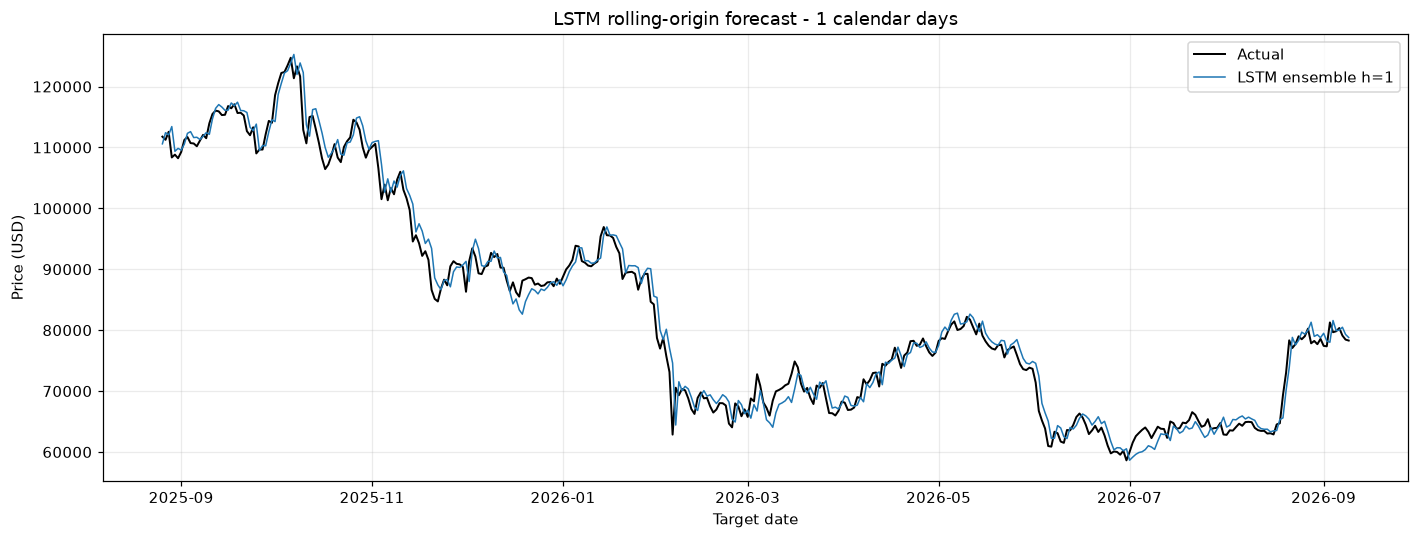

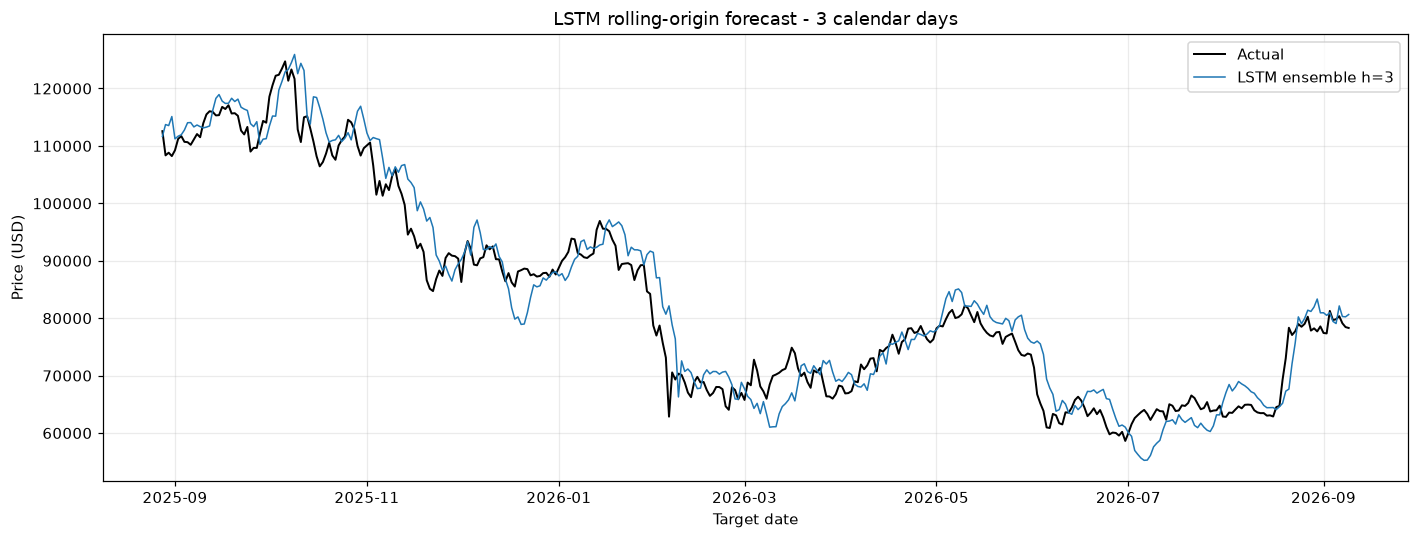

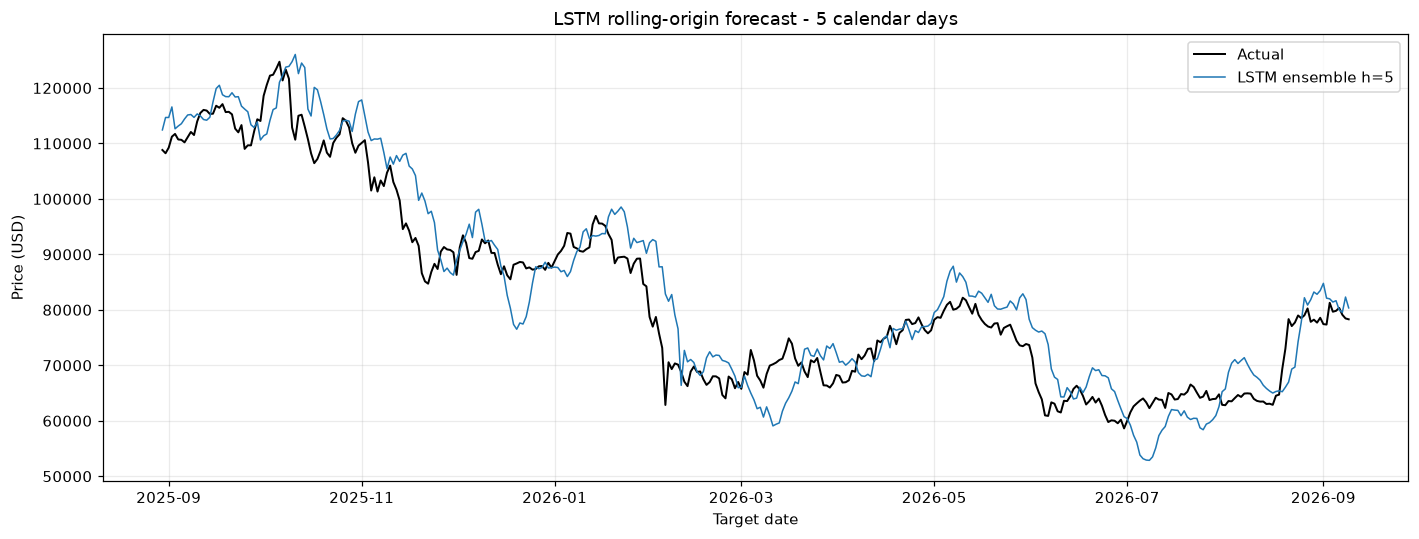

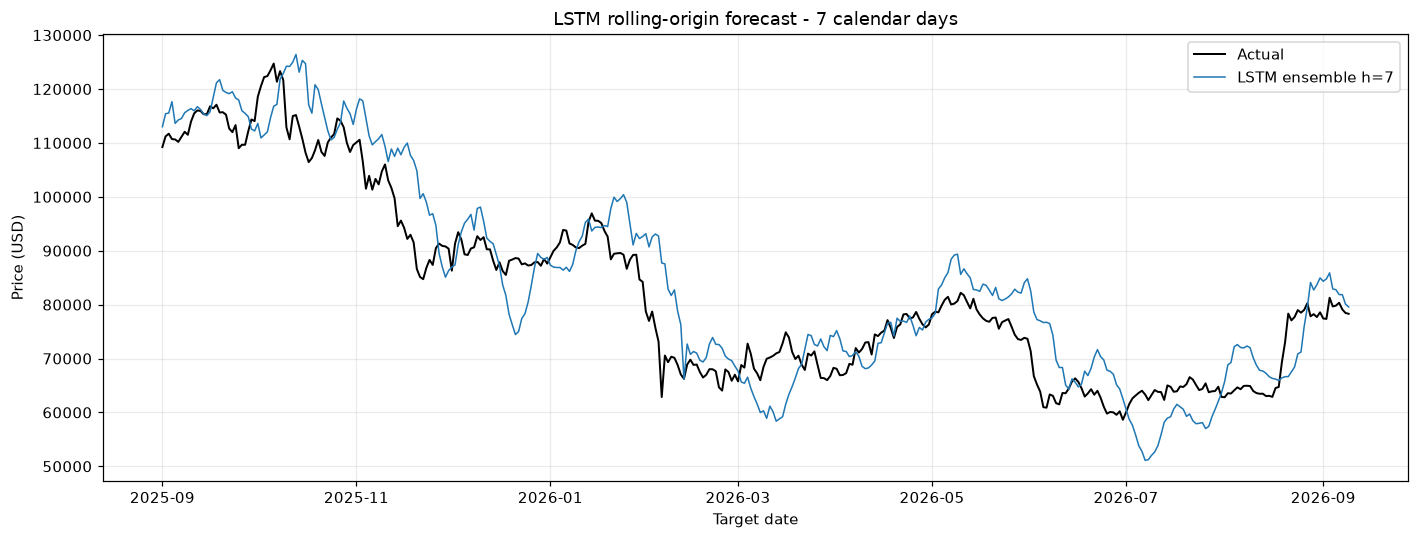

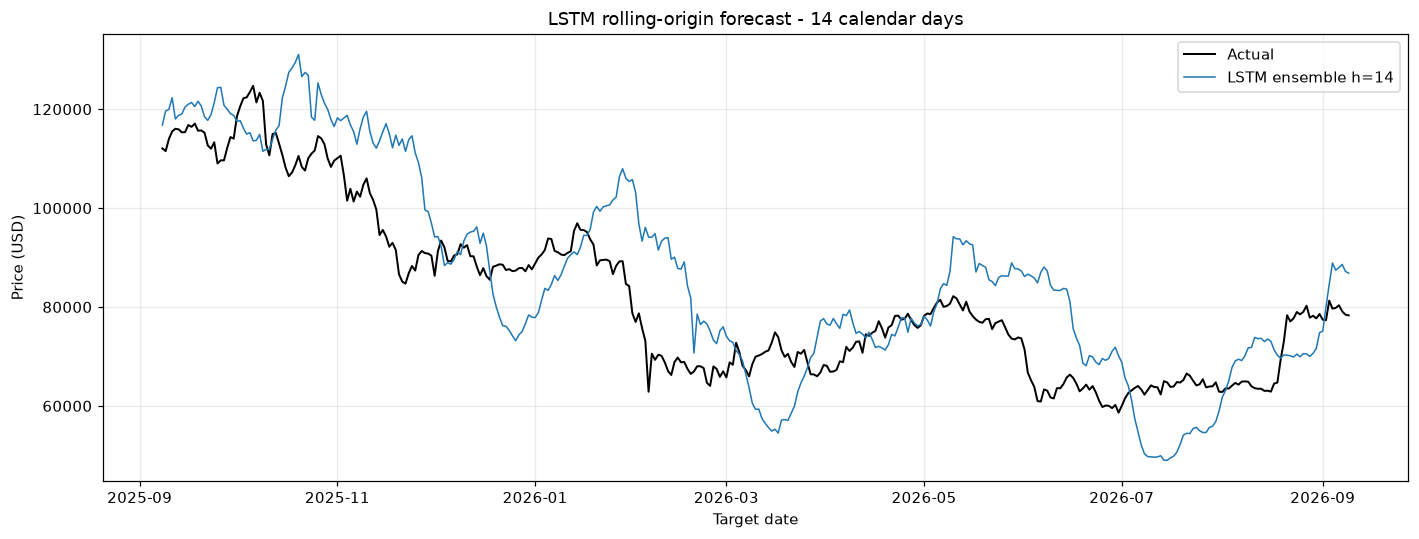

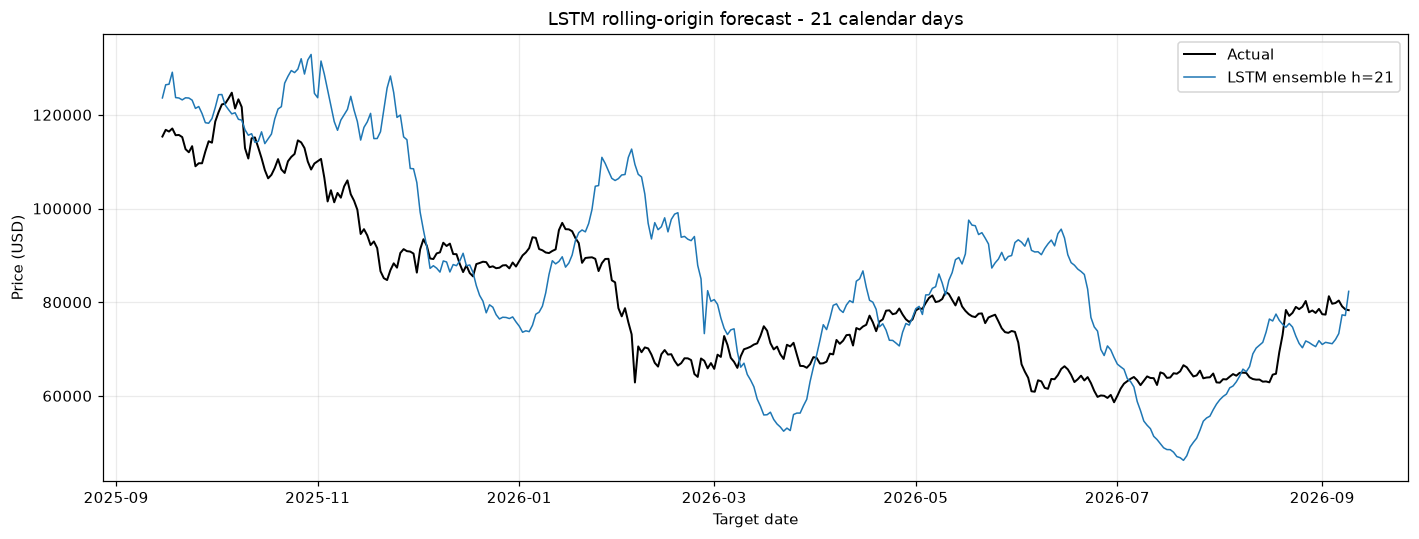

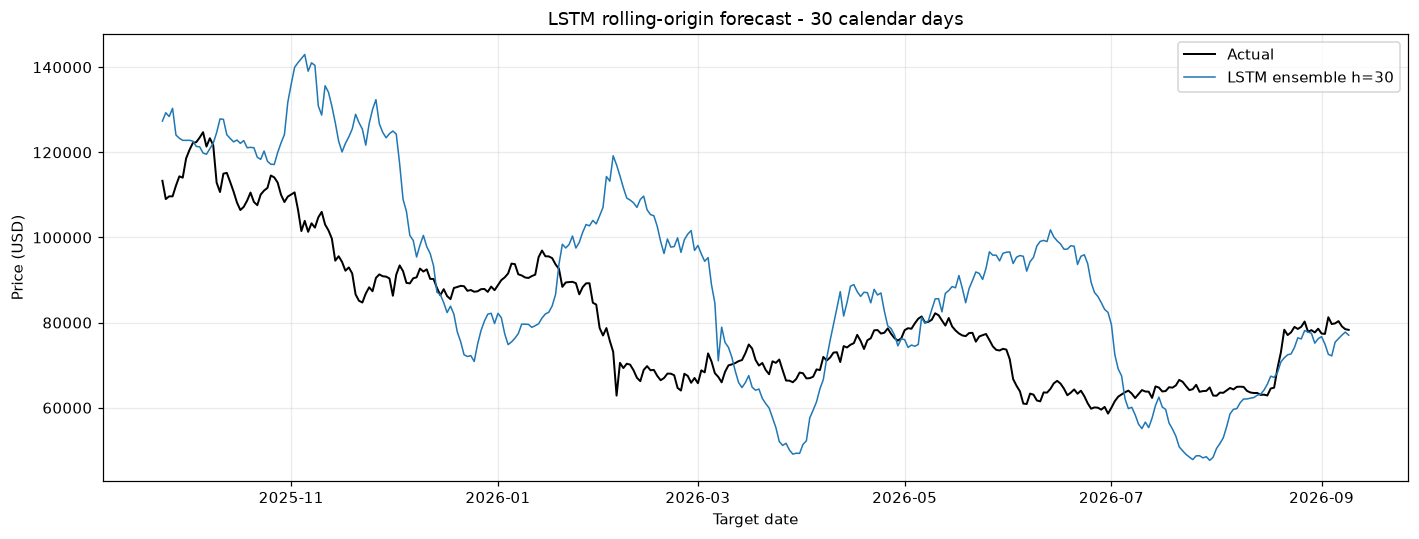

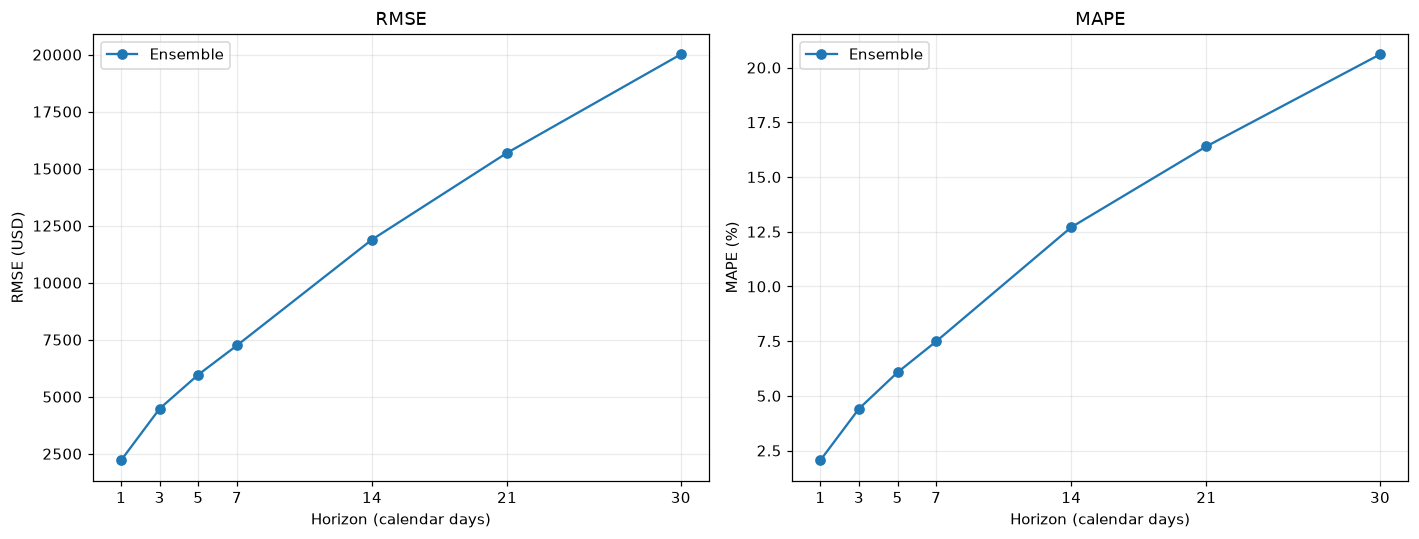

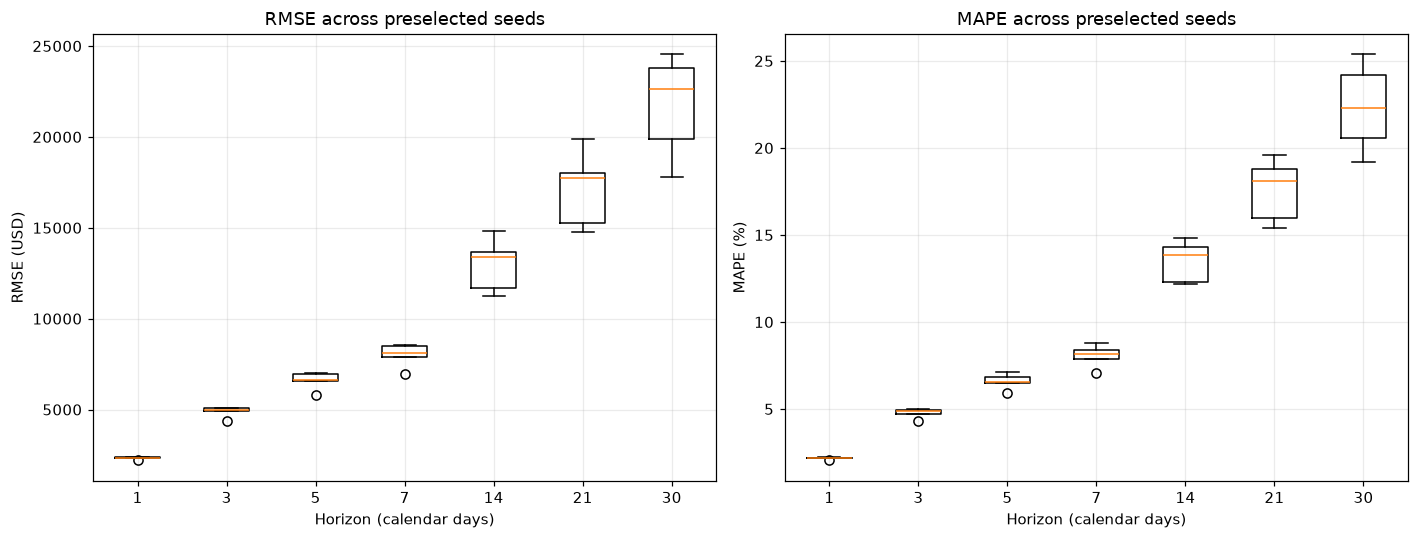

In [14]:
for h in HORIZONS:
    group = forecasts.loc[forecasts['h'].eq(h)]
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.3)
    ax.plot(group['target_date'], group['lstm_fc_ens'], label=f'LSTM ensemble h={h}', linewidth=1)
    if SHOW_NAIVE_REFERENCE:
        ax.plot(group['target_date'], group['price_origin'], label='Naive reference only', alpha=0.5)
    ax.set(title=f'LSTM rolling-origin forecast - {h} calendar days', ylabel='Price (USD)', xlabel='Target date')
    ax.legend()
    save_figure(fig, f'07_forecast_h{h}.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['USD','%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='Ensemble')
    ax.set(title=metric, xlabel='Horizon (calendar days)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '08_error_vs_horizon.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE','MAPE'], ['USD','%']):
    values = [evaluation_seed_individual.loc[evaluation_seed_individual['h'].eq(h),metric].to_numpy()
              for h in HORIZONS]
    ax.boxplot(values, tick_labels=[str(h) for h in HORIZONS])
    ax.set(title=f'{metric} across preselected seeds', xlabel='Horizon (calendar days)', ylabel=f'{metric} ({unit})')
save_figure(fig, '09_seed_variability.png')


## Step 11 - Assumption and Process Checks
Group A structural checks are enforced where data/scaling/windowing/training occur and checked again here.
Mean/std comparability and seed stability are reported descriptively: the specification supplies no numerical acceptance threshold, so their status is REPORTED, not an invented pass/fail rule. Test distributions and seed metrics never alter the model.
Group B diagnoses h=1 ensemble errors on the unscaled log-return target, not USD price errors. Results are reporting-only.
LSTM does not require ARIMA root conditions or normal residuals as a training prerequisite.


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,group,check,statistic,p_value,pass/fail,note
0,A,Chronological unique dates,1.000000,NaN,PASS,
1,A,Train windows exclude test,1516.000000,NaN,PASS,All inputs/targets <= 1516
2,A,Scaler fit excludes test,1516.000000,NaN,PASS,
3,A,Fixed inference weights,1.000000,NaN,PASS,
4,A,Train/test return mean and SD,0.804468,NaN,REPORTED,"Train mean=0.00078411, SD=0.0284756; Test mean..."
5,A,Training loss reduced: seed 0,0.823099,NaN,PASS,First=0.986233; final=0.811768; fixed 50 epochs
6,A,Training loss reduced: seed 1,0.826616,NaN,PASS,First=0.986085; final=0.815113; fixed 50 epochs
7,A,Training loss reduced: seed 2,0.825533,NaN,PASS,First=0.986178; final=0.814122; fixed 50 epochs
8,A,Training loss reduced: seed 3,0.825339,NaN,PASS,First=0.986567; final=0.814252; fixed 50 epochs
9,A,Training loss reduced: seed 4,0.821180,NaN,PASS,First=0.986483; final=0.81008; fixed 50 epochs


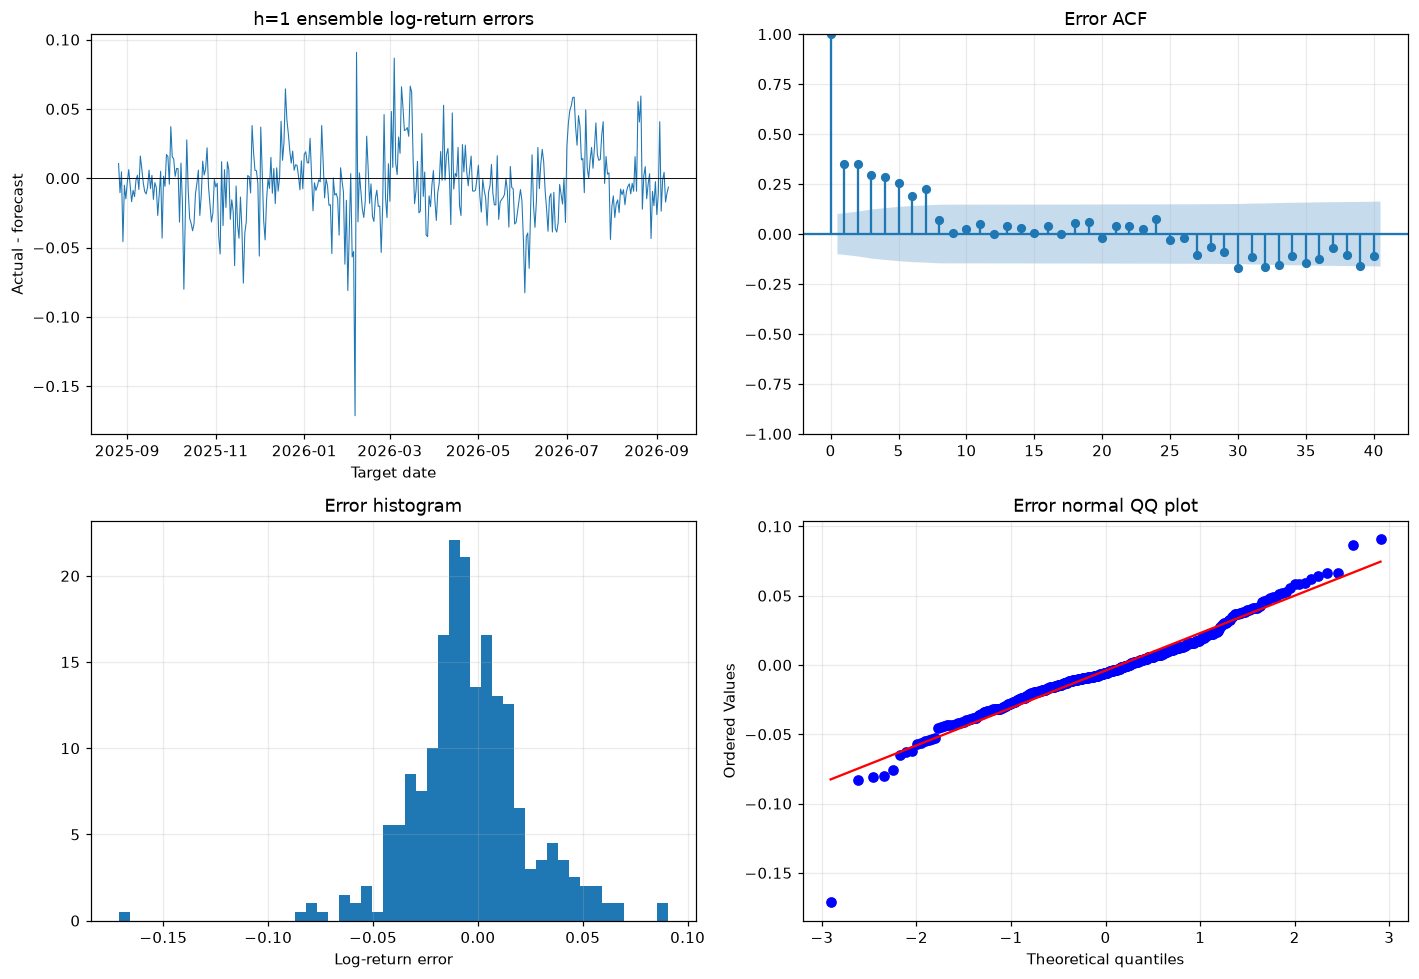

In [15]:
check_rows = []
def add_check(group, check, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    status = 'REPORTED' if passed is None else ('PASS' if bool(passed) else 'FAIL')
    check_rows.append({'group':group, 'check':check, 'statistic':statistic,
                       'p_value':p_value, 'pass/fail':status, 'note':note})
ordered = df.index.is_monotonic_increasing and df.index.is_unique
no_leak = train_input_indices.max() <= TRAIN_END_IDX and train_target_indices.max() <= TRAIN_END_IDX
scaler_train_only = scaler_fit_indices.max() <= TRAIN_END_IDX and int(scaler.n_samples_seen_) == n_train-1
add_check('A','Chronological unique dates', int(ordered), passed=ordered)
add_check('A','Train windows exclude test', int(train_target_indices.max()), passed=no_leak,
          note=f'All inputs/targets <= {TRAIN_END_IDX}')
add_check('A','Scaler fit excludes test', int(scaler_fit_indices.max()), passed=scaler_train_only)
add_check('A','Fixed inference weights', int(weight_audit['unchanged'].all()), passed=weight_audit['unchanged'].all())
train_stats = split_summary.set_index('split').loc['Train']
test_stats = split_summary.set_index('split').loc['Test']
add_check('A','Train/test return mean and SD', float(test_stats['log_ret_std']/train_stats['log_ret_std']),
    note=f'Train mean={train_stats["log_ret_mean"]:.6g}, SD={train_stats["log_ret_std"]:.6g}; '
         f'Test mean={test_stats["log_ret_mean"]:.6g}, SD={test_stats["log_ret_std"]:.6g}. '
         'Statistic=Test/Train SD ratio; no acceptance threshold specified.')
for row in training_audit.itertuples(index=False):
    add_check('A',f'Training loss reduced: seed {row.seed}', row.final_loss/row.first_loss,
        passed=row.loss_reduced, note=f'First={row.first_loss:.6g}; final={row.final_loss:.6g}; fixed {EPOCHS} epochs')
for row in seed_summary.itertuples(index=False):
    add_check('A',f'Seed RMSE SD: h={row.h}', row.RMSE_SD,
              note=f'USD, sample SD across {len(SEEDS)} seeds; no threshold specified')
    add_check('A',f'Seed MAPE SD: h={row.h}', row.MAPE_SD,
              note=f'Percentage points, sample SD across {len(SEEDS)} seeds; no threshold specified')
assert ordered and no_leak and scaler_train_only and weight_audit['unchanged'].all()
assert training_audit['loss_reduced'].all()
assert np.isfinite(seed_summary.select_dtypes('number').to_numpy()).all()

error_dates = df.index[test_origins+1]
e = log_ret.iloc[test_origins+1].to_numpy() - return_predictions_ens[:len(test_origins),0]
assert len(e) == n_test == 380 and np.isfinite(e).all()
ljung_box = acorr_ljungbox(e, lags=[10,20,30], return_df=True)
for lag,row in ljung_box.iterrows():
    add_check('B',f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'], row['lb_pvalue'] > ALPHA,
              'If significant, errors retain autocorrelation; reporting only')
mean_stat, mean_p = stats.ttest_1samp(e, 0)
add_check('B','Residual mean = 0', mean_stat, mean_p, mean_p > ALPHA,
          f'Mean error={e.mean():.6g}; if significant, forecast bias; reporting only')
arch_stat, arch_p, _, _ = het_arch(e, nlags=10)
add_check('B','ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA,
          'If significant, error variance changes over time; reporting only')
jb_stat, jb_p, skew, kurt = jarque_bera(e)
add_check('B','Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
          f'skew={skew:.4g}, kurtosis={kurt:.4g}; reporting only')
assumption_checks = pd.DataFrame(check_rows)
save_table(assumption_checks, 'assumption_checks.csv')
save_table(pd.DataFrame({'target_date':error_dates, 'actual_log_return':log_ret.iloc[test_origins+1].to_numpy(),
    'predicted_log_return':return_predictions_ens[:len(test_origins),0], 'residual':e}), 'residuals_h1.csv')
display(assumption_checks)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0,0].plot(error_dates, e, linewidth=0.7)
axes[0,0].axhline(0, color='black', linewidth=0.6)
axes[0,0].set(title='h=1 ensemble log-return errors', xlabel='Target date', ylabel='Actual - forecast')
plot_acf(e, lags=40, ax=axes[0,1]); axes[0,1].set_title('Error ACF')
axes[1,0].hist(e, bins=50, density=True); axes[1,0].set(title='Error histogram', xlabel='Log-return error')
stats.probplot(e, dist='norm', plot=axes[1,1]); axes[1,1].set_title('Error normal QQ plot')
save_figure(fig, '10_residual_diagnostics.png')


## Step 12 - Summary
The next cell reports the fixed training settings, all process and residual checks, and RMSE/MAPE for every horizon.
It keeps ensemble performance separate from mean +/- SD across seeds. No performance result is used to select a seed, architecture, or epoch count.
A saved Markdown summary from the verified full execution appears below it.


In [16]:
summary_lines = ['### LSTM results from this execution', '',
    f'Fixed settings: lookback={LOOKBACK}, output={MAX_H}, epochs={EPOCHS}, batch={BATCH_SIZE}, '
    f'Adam LR={LR}, dropout={DROPOUT}, seeds={SEEDS}.',
    'Architecture: Input(60,1) -> LSTM(64,tanh,return_sequences=True) -> Dropout(0.1) -> '
    'LSTM(32,tanh) -> Dropout(0.1) -> Dense(30).',
    'Settings were fixed in advance: no validation, early stopping or hyperparameter tuning.',
    f'Chronological Train/Test: {n_train}/{n_test} raw days; {len(train_origins)} training windows.',
    '', '**Group A: process/data checks**']
for row in assumption_checks.loc[assumption_checks['group'].eq('A')].to_dict('records'):
    summary_lines.append(f'- {row["check"]}: {row["pass/fail"]}; statistic={row["statistic"]:.6g}. {row["note"]}')
summary_lines += ['', '**Group B: h=1 log-return residual diagnostics (reporting only)**']
for row in assumption_checks.loc[assumption_checks['group'].eq('B')].to_dict('records'):
    summary_lines.append(f'- {row["check"]}: {row["pass/fail"]}; p={row["p_value"]:.6g}. {row["note"]}')
summary_lines += ['', '**Test metrics: ensemble versus summaries across all five seeds**', '',
    '| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |',
    '|---:|---:|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    seed_row = seed_summary.set_index('h').loc[row.h]
    summary_lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} | '
        f'{seed_row.RMSE_mean:,.2f} +/- {seed_row.RMSE_SD:,.2f} | '
        f'{seed_row.MAPE_mean:.2f} +/- {seed_row.MAPE_SD:.2f} |')
summary_lines += ['', '**Error versus horizon**']
for metric in ['RMSE','MAPE']:
    changes = np.diff(evaluation[metric].to_numpy())
    trend = 'increases at every adjacent requested horizon' if (changes > 0).all() else 'is not strictly increasing across all requested horizons'
    summary_lines.append(f'- {metric} {trend}; h={HORIZONS[0]}: {evaluation[metric].iloc[0]:.2f}, '
                         f'h={HORIZONS[-1]}: {evaluation[metric].iloc[-1]:.2f}.')
summary_lines += ['', '**Future forecasts from the latest observed date**']
for row in future_forecasts.itertuples(index=False):
    summary_lines.append(f'- h={row.h}: origin {row.origin_date.date()}, target {row.target_date.date()}, '
                         f'ensemble forecast {row.lstm_fc_ens:,.2f} USD (no actual available).')
summary_lines += ['', '**Limitations**',
    '- Hyperparameters are not tuned; there is no independent validation estimate or validation-loss curve.',
    '- Univariate Price inputs do not observe news, policy changes, macroeconomic variables or unexpected events.',
    f'- Test prices span {df["Price"].iloc[n_train:].min():,.0f}-{df["Price"].iloc[n_train:].max():,.0f} USD. '
    'This describes regime/level changes, not a formal structural-break test.',
    '- Each seed was trained once; weights and scaler were not retrained during test or future inference.',
    '- Return means/SDs and seed variability have no supplied acceptance thresholds; they are reported, not used to retune.',
    '- Residual autocorrelation, bias, heteroscedasticity and non-normality are reported; failed tests do not discard models.',
    '- Multi-horizon cumulative log-return errors can accumulate. Error samples overlap and sample sizes differ by horizon.',
    '- The five-seed average is an ensemble, not a comparison with another model family; seed dispersion is not a calibrated prediction interval.',
    '- MAPE is a percentage error; 100-MAPE is not statistical accuracy.',
    '', f'Outputs: `{OUTPUT_DIR}`.']
summary_markdown = '\n'.join(summary_lines)
display(Markdown(summary_markdown))
(OUTPUT_DIR / 'summary.md').write_text(summary_markdown, encoding='utf-8')
required_tables = ['split_summary.csv','training_loss.csv','forecasts_long.csv','evaluation_by_horizon.csv',
    'evaluation_by_seed.csv','assumption_checks.csv','future_forecast_by_horizon.csv',
    *[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_figures = ['01_raw_price_volume.png','02_log_return.png','03_return_distribution.png',
    '04_acf_log_return.png','05_train_test_split.png','06_training_loss.png',
    *[f'07_forecast_h{h}.png' for h in HORIZONS], '08_error_vs_horizon.png',
    '09_seed_variability.png','10_residual_diagnostics.png']
required_tables += [f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]
assert all((TABLE_DIR / file).is_file() for file in required_tables)
assert all((FIGURE_DIR / file).is_file() for file in required_figures)
assert all((MODEL_DIR / f'lstm_seed{seed}.weights.h5').is_file() for seed in SEEDS)
assert (MODEL_DIR / 'scaler_params.json').is_file() and (MODEL_DIR / 'model_architecture.txt').is_file()
assert all(weights_digest(models[seed]) == frozen_weight_hashes[seed] for seed in SEEDS)
print('Completed: all required outputs saved; weights and scaler stayed fixed.')


### LSTM results from this execution

Fixed settings: lookback=60, output=30, epochs=50, batch=32, Adam LR=0.001, dropout=0.1, seeds=[0, 1, 2, 3, 4].
Architecture: Input(60,1) -> LSTM(64,tanh,return_sequences=True) -> Dropout(0.1) -> LSTM(32,tanh) -> Dropout(0.1) -> Dense(30).
Settings were fixed in advance: no validation, early stopping or hyperparameter tuning.
Chronological Train/Test: 1517/380 raw days; 1427 training windows.

**Group A: process/data checks**
- Chronological unique dates: PASS; statistic=1. 
- Train windows exclude test: PASS; statistic=1516. All inputs/targets <= 1516
- Scaler fit excludes test: PASS; statistic=1516. 
- Fixed inference weights: PASS; statistic=1. 
- Train/test return mean and SD: REPORTED; statistic=0.804468. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Training loss reduced: seed 0: PASS; statistic=0.823099. First=0.986233; final=0.811768; fixed 50 epochs
- Training loss reduced: seed 1: PASS; statistic=0.826616. First=0.986085; final=0.815113; fixed 50 epochs
- Training loss reduced: seed 2: PASS; statistic=0.825533. First=0.986178; final=0.814122; fixed 50 epochs
- Training loss reduced: seed 3: PASS; statistic=0.825339. First=0.986567; final=0.814252; fixed 50 epochs
- Training loss reduced: seed 4: PASS; statistic=0.82118. First=0.986483; final=0.81008; fixed 50 epochs
- Seed RMSE SD: h=1: REPORTED; statistic=71.2651. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=1: REPORTED; statistic=0.0680115. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=3: REPORTED; statistic=292.55. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=3: REPORTED; statistic=0.271672. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=5: REPORTED; statistic=474.627. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=5: REPORTED; statistic=0.445898. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=7: REPORTED; statistic=652.819. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=7: REPORTED; statistic=0.628992. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=14: REPORTED; statistic=1476.9. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=14: REPORTED; statistic=1.20757. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=21: REPORTED; statistic=2099.41. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=21: REPORTED; statistic=1.82524. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=30: REPORTED; statistic=2823.47. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=30: REPORTED; statistic=2.52276. Percentage points, sample SD across 5 seeds; no threshold specified

**Group B: h=1 log-return residual diagnostics (reporting only)**
- Ljung-Box lag 10: FAIL; p=1.39944e-41. If significant, errors retain autocorrelation; reporting only
- Ljung-Box lag 20: FAIL; p=1.13737e-36. If significant, errors retain autocorrelation; reporting only
- Ljung-Box lag 30: FAIL; p=9.73328e-37. If significant, errors retain autocorrelation; reporting only
- Residual mean = 0: FAIL; p=0.00476159. Mean error=-0.00400966; if significant, forecast bias; reporting only
- ARCH LM (10 lags): FAIL; p=9.56853e-06. If significant, error variance changes over time; reporting only
- Jarque-Bera: FAIL; p=7.98476e-55. skew=-0.3082, kurtosis=6.918; reporting only

**Test metrics: ensemble versus summaries across all five seeds**

| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|---:|---:|---:|
| 1 | 380 | 2,211.03 | 2.05 | 2,332.52 +/- 71.27 | 2.16 +/- 0.07 |
| 3 | 378 | 4,478.93 | 4.41 | 4,890.25 +/- 292.55 | 4.76 +/- 0.27 |
| 5 | 376 | 5,966.77 | 6.07 | 6,586.23 +/- 474.63 | 6.59 +/- 0.45 |
| 7 | 374 | 7,246.53 | 7.48 | 8,003.96 +/- 652.82 | 8.06 +/- 0.63 |
| 14 | 367 | 11,889.33 | 12.70 | 12,953.78 +/- 1,476.90 | 13.50 +/- 1.21 |
| 21 | 360 | 15,693.28 | 16.40 | 17,125.88 +/- 2,099.41 | 17.57 +/- 1.83 |
| 30 | 351 | 20,010.38 | 20.60 | 21,726.88 +/- 2,823.47 | 22.33 +/- 2.52 |

**Error versus horizon**
- RMSE increases at every adjacent requested horizon; h=1: 2211.03, h=30: 20010.38.
- MAPE increases at every adjacent requested horizon; h=1: 2.05, h=30: 20.60.

**Future forecasts from the latest observed date**
- h=1: origin 2026-09-09, target 2026-09-10, ensemble forecast 78,827.64 USD (no actual available).
- h=3: origin 2026-09-09, target 2026-09-12, ensemble forecast 79,602.89 USD (no actual available).
- h=5: origin 2026-09-09, target 2026-09-14, ensemble forecast 79,977.01 USD (no actual available).
- h=7: origin 2026-09-09, target 2026-09-16, ensemble forecast 79,820.56 USD (no actual available).
- h=14: origin 2026-09-09, target 2026-09-23, ensemble forecast 79,064.02 USD (no actual available).
- h=21: origin 2026-09-09, target 2026-09-30, ensemble forecast 78,065.43 USD (no actual available).
- h=30: origin 2026-09-09, target 2026-10-09, ensemble forecast 78,360.42 USD (no actual available).

**Limitations**
- Hyperparameters are not tuned; there is no independent validation estimate or validation-loss curve.
- Univariate Price inputs do not observe news, policy changes, macroeconomic variables or unexpected events.
- Test prices span 58,631-124,725 USD. This describes regime/level changes, not a formal structural-break test.
- Each seed was trained once; weights and scaler were not retrained during test or future inference.
- Return means/SDs and seed variability have no supplied acceptance thresholds; they are reported, not used to retune.
- Residual autocorrelation, bias, heteroscedasticity and non-normality are reported; failed tests do not discard models.
- Multi-horizon cumulative log-return errors can accumulate. Error samples overlap and sample sizes differ by horizon.
- The five-seed average is an ensemble, not a comparison with another model family; seed dispersion is not a calibrated prediction interval.
- MAPE is a percentage error; 100-MAPE is not statistical accuracy.

Outputs: `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_lstm`.

Completed: all required outputs saved; weights and scaler stayed fixed.


### Saved summary from the verified full execution

### LSTM results from this execution

Fixed settings: lookback=60, output=30, epochs=50, batch=32, Adam LR=0.001, dropout=0.1, seeds=[0, 1, 2, 3, 4].
Architecture: Input(60,1) -> LSTM(64,tanh,return_sequences=True) -> Dropout(0.1) -> LSTM(32,tanh) -> Dropout(0.1) -> Dense(30).
Settings were fixed in advance: no validation, early stopping or hyperparameter tuning.
Chronological Train/Test: 1517/380 raw days; 1427 training windows.

**Group A: process/data checks**
- Chronological unique dates: PASS; statistic=1. 
- Train windows exclude test: PASS; statistic=1516. All inputs/targets <= 1516
- Scaler fit excludes test: PASS; statistic=1516. 
- Fixed inference weights: PASS; statistic=1. 
- Train/test return mean and SD: REPORTED; statistic=0.804468. Train mean=0.00078411, SD=0.0284756; Test mean=-0.000897492, SD=0.0229077. Statistic=Test/Train SD ratio; no acceptance threshold specified.
- Training loss reduced: seed 0: PASS; statistic=0.823099. First=0.986233; final=0.811768; fixed 50 epochs
- Training loss reduced: seed 1: PASS; statistic=0.826616. First=0.986085; final=0.815113; fixed 50 epochs
- Training loss reduced: seed 2: PASS; statistic=0.825533. First=0.986178; final=0.814122; fixed 50 epochs
- Training loss reduced: seed 3: PASS; statistic=0.825339. First=0.986567; final=0.814252; fixed 50 epochs
- Training loss reduced: seed 4: PASS; statistic=0.82118. First=0.986483; final=0.81008; fixed 50 epochs
- Seed RMSE SD: h=1: REPORTED; statistic=71.2651. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=1: REPORTED; statistic=0.0680115. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=3: REPORTED; statistic=292.55. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=3: REPORTED; statistic=0.271672. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=5: REPORTED; statistic=474.627. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=5: REPORTED; statistic=0.445898. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=7: REPORTED; statistic=652.819. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=7: REPORTED; statistic=0.628992. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=14: REPORTED; statistic=1476.9. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=14: REPORTED; statistic=1.20757. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=21: REPORTED; statistic=2099.41. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=21: REPORTED; statistic=1.82524. Percentage points, sample SD across 5 seeds; no threshold specified
- Seed RMSE SD: h=30: REPORTED; statistic=2823.47. USD, sample SD across 5 seeds; no threshold specified
- Seed MAPE SD: h=30: REPORTED; statistic=2.52276. Percentage points, sample SD across 5 seeds; no threshold specified

**Group B: h=1 log-return residual diagnostics (reporting only)**
- Ljung-Box lag 10: FAIL; p=1.39944e-41. If significant, errors retain autocorrelation; reporting only
- Ljung-Box lag 20: FAIL; p=1.13737e-36. If significant, errors retain autocorrelation; reporting only
- Ljung-Box lag 30: FAIL; p=9.73328e-37. If significant, errors retain autocorrelation; reporting only
- Residual mean = 0: FAIL; p=0.00476159. Mean error=-0.00400966; if significant, forecast bias; reporting only
- ARCH LM (10 lags): FAIL; p=9.56853e-06. If significant, error variance changes over time; reporting only
- Jarque-Bera: FAIL; p=7.98476e-55. skew=-0.3082, kurtosis=6.918; reporting only

**Test metrics: ensemble versus summaries across all five seeds**

| h (days) | n | Ensemble RMSE (USD) | Ensemble MAPE (%) | Seed RMSE mean +/- SD (USD) | Seed MAPE mean +/- SD (%) |
|---:|---:|---:|---:|---:|---:|
| 1 | 380 | 2,211.03 | 2.05 | 2,332.52 +/- 71.27 | 2.16 +/- 0.07 |
| 3 | 378 | 4,478.93 | 4.41 | 4,890.25 +/- 292.55 | 4.76 +/- 0.27 |
| 5 | 376 | 5,966.77 | 6.07 | 6,586.23 +/- 474.63 | 6.59 +/- 0.45 |
| 7 | 374 | 7,246.53 | 7.48 | 8,003.96 +/- 652.82 | 8.06 +/- 0.63 |
| 14 | 367 | 11,889.33 | 12.70 | 12,953.78 +/- 1,476.90 | 13.50 +/- 1.21 |
| 21 | 360 | 15,693.28 | 16.40 | 17,125.88 +/- 2,099.41 | 17.57 +/- 1.83 |
| 30 | 351 | 20,010.38 | 20.60 | 21,726.88 +/- 2,823.47 | 22.33 +/- 2.52 |

**Error versus horizon**
- RMSE increases at every adjacent requested horizon; h=1: 2211.03, h=30: 20010.38.
- MAPE increases at every adjacent requested horizon; h=1: 2.05, h=30: 20.60.

**Future forecasts from the latest observed date**
- h=1: origin 2026-09-09, target 2026-09-10, ensemble forecast 78,827.64 USD (no actual available).
- h=3: origin 2026-09-09, target 2026-09-12, ensemble forecast 79,602.89 USD (no actual available).
- h=5: origin 2026-09-09, target 2026-09-14, ensemble forecast 79,977.01 USD (no actual available).
- h=7: origin 2026-09-09, target 2026-09-16, ensemble forecast 79,820.56 USD (no actual available).
- h=14: origin 2026-09-09, target 2026-09-23, ensemble forecast 79,064.02 USD (no actual available).
- h=21: origin 2026-09-09, target 2026-09-30, ensemble forecast 78,065.43 USD (no actual available).
- h=30: origin 2026-09-09, target 2026-10-09, ensemble forecast 78,360.42 USD (no actual available).

**Limitations**
- Hyperparameters are not tuned; there is no independent validation estimate or validation-loss curve.
- Univariate Price inputs do not observe news, policy changes, macroeconomic variables or unexpected events.
- Test prices span 58,631-124,725 USD. This describes regime/level changes, not a formal structural-break test.
- Each seed was trained once; weights and scaler were not retrained during test or future inference.
- Return means/SDs and seed variability have no supplied acceptance thresholds; they are reported, not used to retune.
- Residual autocorrelation, bias, heteroscedasticity and non-normality are reported; failed tests do not discard models.
- Multi-horizon cumulative log-return errors can accumulate. Error samples overlap and sample sizes differ by horizon.
- The five-seed average is an ensemble, not a comparison with another model family; seed dispersion is not a calibrated prediction interval.
- MAPE is a percentage error; 100-MAPE is not statistical accuracy.

Outputs: `C:\Users\User\Desktop\PROJECT_2026\OUTPUT\outputs_lstm`.

### Method references
- [TensorFlow deterministic operations](https://www.tensorflow.org/api_docs/python/tf/config/experimental/enable_op_determinism)
- [Keras Model training, prediction and weights](https://www.tensorflow.org/api_docs/python/tf/keras/Model)
